# xSIMPSON v3: batting-only, contact-adjusted prototype

The ground-ball singles model and its saved results remain a diagnostic below.
The second section extends accounting to all fair contact, including home runs,
plus observed unintentional walks and HBP per official PA.

**2026 is a development evaluation**, because it helped motivate this project.
Train on 2024-2025, exclude Chandler Simpson (802415) from all fitting and fallback
estimates, and retain the existing degree-2 logistic settings without 2026 tuning.
This is contact-adjusted accounting using observed contact, not a prospective skill
forecast. Baserunning and xSIMPSON+ remain later stages.

## Ground-ball singles diagnostic

The original quadratic sections are the recorded benchmark. The final diagnostic
section compares one fixed challenger using 2024 training / 2025 validation and
updates the final batting leaderboard with the selected approach. Earlier
baseline/full metrics remain quadratic diagnostics. No 2026 or Simpson result
selects the model.


In [1]:
import csv
import time
import joblib
from threadpoolctl import threadpool_limits
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.calibration import CalibrationDisplay, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

In [2]:
TRAIN_YEARS = [2024, 2025]
TEST_YEAR = 2026
SIMPSON_ID = 802415
DOWNLOAD = False
YEARS = TRAIN_YEARS + [TEST_YEAR]
SPEED_YEARS = sorted({year - 1 for year in YEARS})
BATCH_DAYS = 14
MAX_RETRIES = 3
# Avoid future dates and today's incomplete games.
AS_OF_DATE = (
    pd.Timestamp.now(tz="America/New_York").normalize().tz_localize(None)
    - pd.Timedelta(days=1)
)

In [3]:
# Support a kernel started in either the project root or SIMPSONv3.
NOTEBOOK_DIR = Path.cwd().resolve()
if (NOTEBOOK_DIR / "SIMPSONv3" / "main.ipynb").is_file():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "SIMPSONv3"
if not (NOTEBOOK_DIR / "main.ipynb").is_file():
    raise FileNotFoundError("Start the kernel in SIMPSON or SIMPSONv3.")
PROJECT_DIR = NOTEBOOK_DIR.parent
PROJECT_DIR = NOTEBOOK_DIR.parent
PROJECT_DIR = NOTEBOOK_DIR.parent
PROJECT_DIR = NOTEBOOK_DIR.parent
DATA_DIR = (PROJECT_DIR / "data").resolve()
RESULTS_DIR = PROJECT_DIR / "results"
CHARTS_DIR = PROJECT_DIR / "charts"
MODELS_DIR = PROJECT_DIR / "models"
BENCHMARK_DIR = PROJECT_DIR / "benchmarks" / "frozen_quadratic_benchmark"
for directory in [DATA_DIR, RESULTS_DIR, CHARTS_DIR, MODELS_DIR, BENCHMARK_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = RESULTS_DIR / "xsimpson_v3_ground_ball_results.csv"

pitch_keys = ["game_pk", "at_bat_number", "pitch_number"]
required_columns = [
    "game_date", *pitch_keys, "batter", "events", "bb_type",
    "launch_speed", "launch_angle", "stand", "hc_x", "hc_y", "game_type", "des",
]
speed_columns = ["player_id", "season", "sprint_speed"]
print("Data folder:", DATA_DIR)
print("Player-table destination:", RESULTS_PATH)

Data folder: C:\Users\isaac\CodingProjects\SIMPSON\data
Player-table destination: C:\Users\isaac\CodingProjects\SIMPSON\results\xsimpson_v3_ground_ball_results.csv


In [4]:
def fetch_with_retries(fetch, *args, **kwargs):
    for attempt in range(MAX_RETRIES):
        try:
            return fetch(*args, **kwargs)
        except (requests.exceptions.RequestException, pd.errors.EmptyDataError):
            if attempt == MAX_RETRIES - 1:
                raise
            delay = 2 ** (attempt + 1)
            print(f"Request failed; retrying in {delay} seconds.", flush=True)
            time.sleep(delay)

In [5]:
def download_statcast_year(year):
    output_path = DATA_DIR / f"statcast_{year}.csv"
    if output_path.is_file() and year < AS_OF_DATE.year:
        try:
            sample = pd.read_csv(output_path, nrows=1)
            if not sample.empty and set(required_columns).issubset(sample.columns):
                print(f"Using {output_path.name}", flush=True)
                return
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass

    start_date = pd.Timestamp(year=year, month=3, day=1)
    end_date = min(pd.Timestamp(year=year, month=11, day=30), AS_OF_DATE)
    partial_path = output_path.with_suffix(".partial.csv")
    wrote_batch = False
    for batch_start in pd.date_range(start_date, end_date, freq=f"{BATCH_DAYS}D"):
        batch_end = min(batch_start + pd.Timedelta(days=BATCH_DAYS - 1), end_date)
        print(f"{year}: {batch_start.date()} through {batch_end.date()}", flush=True)
        batch = fetch_with_retries(
            statcast,
            batch_start.strftime("%Y-%m-%d"),
            batch_end.strftime("%Y-%m-%d"),
            parallel=True,
            verbose=False,
        )
        if batch.empty:
            continue
        missing = sorted(set(required_columns) - set(batch.columns))
        if missing:
            raise ValueError(f"Statcast {year} batch missing columns: {missing}")
        # The first nonempty batch writes the header; later batches append.
        batch[required_columns].to_csv(
            partial_path,
            mode="a" if wrote_batch else "w",
            header=not wrote_batch,
            index=False,
        )
        wrote_batch = True
    if not wrote_batch:
        raise ValueError(f"No Statcast data returned for {year}; no file published.")
    partial_path.replace(output_path)
    print(f"Saved {output_path.name}", flush=True)

In [6]:
if DOWNLOAD:
    from pybaseball import cache, statcast, statcast_sprint_speed

    cache.enable()
    for year in YEARS:
        download_statcast_year(year)

In [7]:
if DOWNLOAD:
    speed_path = DATA_DIR / "sprint_speed.csv"
    cached_speed = pd.DataFrame()
    if speed_path.is_file():
        try:
            cached_speed = pd.read_csv(speed_path)
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass
    speed_ready = (
        set(speed_columns).issubset(cached_speed.columns)
        and set(SPEED_YEARS).issubset(cached_speed["season"].dropna().unique())
    )
    if not speed_ready:
        speed_download = pd.concat(
            [
                fetch_with_retries(statcast_sprint_speed, year).assign(season=year)
                for year in SPEED_YEARS
            ],
            ignore_index=True,
        )
        if not set(speed_columns).issubset(speed_download.columns):
            raise ValueError("Sprint Speed response is missing required columns.")
        if set(speed_download["season"].unique()) != set(SPEED_YEARS):
            raise ValueError("Sprint Speed response is missing required seasons.")
        partial_speed_path = speed_path.with_suffix(".partial.csv")
        speed_download.to_csv(partial_speed_path, index=False)
        partial_speed_path.replace(speed_path)
    print("Sprint Speed seasons required:", SPEED_YEARS)

In [8]:
def load_csv(path, columns):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run downloads with DOWNLOAD = True.")
    with path.open(encoding="utf-8-sig", newline="") as handle:
        header = next(csv.reader(handle), [])
    missing = sorted(set(columns) - set(header))
    if missing or len(header) != len(set(header)):
        raise ValueError(
            f"{path.name}: missing columns {missing} or duplicate header names. "
            "Download the CSV again."
        )
    try:
        data = pd.read_csv(path, usecols=columns, low_memory=False)
    except (pd.errors.EmptyDataError, pd.errors.ParserError) as error:
        raise ValueError(f"{path.name}: empty or malformed CSV.") from error
    if data.empty:
        raise ValueError(f"{path.name}: CSV has a header but no rows.")
    return data

In [9]:
season_frames = []
data_checks = []
for year in YEARS:
    path = DATA_DIR / f"statcast_{year}.csv"
    frame = load_csv(path, required_columns)
    frame["game_date"] = pd.to_datetime(frame["game_date"], errors="raise")
    if not frame["game_date"].dt.year.eq(year).all():
        raise ValueError(f"{path.name}: missing dates or dates outside {year}.")
    for column in pitch_keys + ["batter", "launch_speed", "launch_angle", "hc_x", "hc_y"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[pitch_keys + ["batter"]].isna().any().any():
        raise ValueError(f"{path.name}: missing pitch or batter keys.")
    duplicate_pitches = int(frame.duplicated(pitch_keys).sum())
    if duplicate_pitches:
        raise ValueError(f"{path.name}: {duplicate_pitches} duplicate pitch records.")
    data_checks.append({
        "season": year, "rows": len(frame), "duplicate_pitches": duplicate_pitches,
        "first_date": frame["game_date"].min(),
        "last_date": frame["game_date"].max(),
    })
    season_frames.append(frame)
plays = pd.concat(season_frames, ignore_index=True)
assert not plays.duplicated(pitch_keys).any(), "Duplicate pitch keys across files"
del season_frames, frame

data_checks = pd.DataFrame(data_checks).set_index("season")
display(data_checks)
print("Verified headers, expected seasons, and unique game/at-bat/pitch keys.")

,rows,duplicate_pitches,first_date,last_date
season,,,,
2024,760249,0,2024-03-15,2024-10-30
2025,770795,0,2025-03-15,2025-11-01
2026,766340,0,2026-03-15,2026-10-28


Verified headers, expected seasons, and unique game/at-bat/pitch keys.


In [10]:
speed = load_csv(DATA_DIR / "sprint_speed.csv", speed_columns)
for column in speed_columns:
    speed[column] = pd.to_numeric(speed[column], errors="raise")
if speed[["player_id", "season"]].isna().any().any():
    raise ValueError("sprint_speed.csv contains missing player or season keys.")
missing_seasons = sorted(set(SPEED_YEARS) - set(speed["season"].unique()))
if missing_seasons:
    raise ValueError(f"sprint_speed.csv is missing preceding seasons: {missing_seasons}")
speed = speed.loc[speed["season"].isin(SPEED_YEARS)].copy()
if speed.duplicated(["player_id", "season"]).any():
    raise ValueError("sprint_speed.csv has duplicate player-season keys.")
display(speed.groupby("season").agg(
    players=("player_id", "size"), available_speeds=("sprint_speed", "count"),
))

,players,available_speeds
season,,
2023,583,583
2024,566,566
2025,579,579


In [11]:
# Truncated appearances are not completed PA and must not inflate PA totals.
plate_appearances = plays.loc[
    plays["game_type"].eq("R") & plays["events"].notna()
    & plays["events"].ne("truncated_pa"),
    required_columns,
].copy()
assert not plate_appearances.duplicated(["game_pk", "at_bat_number"]).any()
plate_appearances["season"] = plate_appearances["game_date"].dt.year
plate_appearances["speed_season"] = plate_appearances["season"] - 1

speed_keys = speed.rename(
    columns={"player_id": "batter", "season": "source_speed_season"}
)
plate_appearances = plate_appearances.merge(
    speed_keys[["batter", "source_speed_season", "sprint_speed"]],
    left_on=["batter", "speed_season"],
    right_on=["batter", "source_speed_season"],
    how="left", validate="many_to_one",
)
matched_speed = plate_appearances["source_speed_season"].notna()
assert plate_appearances.loc[matched_speed, "source_speed_season"].eq(
    plate_appearances.loc[matched_speed, "season"] - 1
).all(), "A speed record came from the wrong season"
display(plate_appearances.groupby("season").agg(
    completed_PA=("batter", "size"),
    matched_prior_speed_records=("source_speed_season", "count"),
    available_speeds=("sprint_speed", "count"),
))
print("Sprint Speed joined by batter ID and preceding season only.")

,completed_PA,matched_prior_speed_records,available_speeds
season,,,
2024,182449,165182,165182
2025,182926,161167,161167
2026,183849,159822,159822


Sprint Speed joined by batter ID and preceding season only.


In [12]:
grounders = plate_appearances.loc[
    plate_appearances["bb_type"].eq("ground_ball")
].copy()
grounders["single"] = grounders["events"].eq("single").astype(int)
grounders["missing_coordinates"] = grounders[["hc_x", "hc_y"]].isna().any(axis=1)
display(grounders.groupby(["season", "single"]).agg(
    grounders=("single", "size"),
    missing_coordinates=("missing_coordinates", "mean"),
    available_speeds=("sprint_speed", "count"),
))

grounders  missing_coordinates  available_speeds
season single                                                  
2024   0           41197             0.000073             37273
       1           11889             0.000252             10769
2025   0           41072             0.000292             35855
       1           11848             0.000084             10393
2026   0           40926             0.000220             35466
       1           11873             0.000084             10240

In [13]:
model_data = grounders.dropna(
    subset=["launch_speed", "launch_angle", "hc_x", "hc_y", "stand"]
).copy()

# Approximate home plate origin in Savant chart coordinates.
model_data["spray_angle"] = np.degrees(
    np.arctan2(model_data["hc_x"] - 125.42, 198.27 - model_data["hc_y"])
)
model_data["left_handed"] = model_data["stand"].eq("L").astype(int)
model_data["speed_missing"] = model_data["sprint_speed"].isna().astype(int)

In [14]:
assert max(TRAIN_YEARS) < TEST_YEAR
train_mask = (
    model_data["season"].isin(TRAIN_YEARS)
    & model_data["batter"].ne(SIMPSON_ID)
)
train_data = model_data.loc[train_mask].copy()
test_data = model_data.loc[model_data["season"].eq(TEST_YEAR)].copy()
assert len(train_data) and len(test_data), "Check years and data coverage"
assert train_data["single"].nunique() == 2
assert not train_data["batter"].eq(SIMPSON_ID).any()

# Estimate the replacement before changing either split; never use 2026 speed.
median_speed = train_data["sprint_speed"].median()
assert pd.notna(median_speed), "No training speed data matched"
for frame in (train_data, test_data):
    frame["sprint_speed"] = frame["sprint_speed"].fillna(median_speed)
print("Training rows:", len(train_data), "Development evaluation rows:", len(test_data))
print("Simpson training rows:", train_data["batter"].eq(SIMPSON_ID).sum())
print("Training-only median Sprint Speed:", median_speed)
print("Missing-speed fraction, train:", train_data["speed_missing"].mean())
print("Missing-speed fraction, 2026:", test_data["speed_missing"].mean())

Training rows: 105003 Development evaluation rows: 52310
Simpson training rows: 0
Training-only median Sprint Speed: 27.5
Missing-speed fraction, train: 0.10850166185728027
Missing-speed fraction, 2026: 0.1344484802141082


In [15]:
baseline_columns = [
    "launch_speed", "launch_angle", "sprint_speed", "left_handed", "speed_missing",
]
full_columns = baseline_columns + ["spray_angle"]
scores = []

# Preserve the existing degree, C, and iteration limit; no 2026 tuning.
# Both models include degree-2 terms. The full model adds direction interactions,
# including spray_angle * sprint_speed and spray_angle * left_handed.
for name, columns in [("baseline", baseline_columns), ("full", full_columns)]:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=2000),
    )
    model.fit(train_data[columns], train_data["single"])
    assert model.named_steps["standardscaler-1"].n_samples_seen_ == len(train_data)
    test_data[name] = model.predict_proba(test_data[columns])[:, 1]
    assert np.isfinite(test_data[name]).all() and test_data[name].between(0, 1).all()
    scores.append({
        "model": name,
        "Brier": brier_score_loss(test_data["single"], test_data[name]),
        "log_loss": log_loss(test_data["single"], test_data[name], labels=[0, 1]),
    })
print("Both models scored the same", len(test_data), "2026 ground balls.")

Both models scored the same 52310 2026 ground balls.


In [16]:
score_table = pd.DataFrame(scores).set_index("model")
metric_comparison = score_table.T.rename_axis("metric")
metric_comparison["full_minus_baseline"] = (
    metric_comparison["full"] - metric_comparison["baseline"]
)
metric_comparison["improvement_percent"] = (
    -100 * metric_comparison["full_minus_baseline"] / metric_comparison["baseline"]
)
metric_comparison["full_improves"] = metric_comparison["full_minus_baseline"].lt(0)
print("Ground-ball prototype: 2026 development evaluation; lower loss is better.")
display(metric_comparison.round(6))
metric_comparison.to_csv(RESULTS_DIR / "xsimpson_v3_ground_ball_metrics.csv")

Ground-ball prototype: 2026 development evaluation; lower loss is better.


model,baseline,full,full_minus_baseline,improvement_percent,full_improves
metric,,,,,
Brier,0.153997,0.149218,-0.004779,3.103346,True
log_loss,0.476124,0.464258,-0.011865,2.492082,True


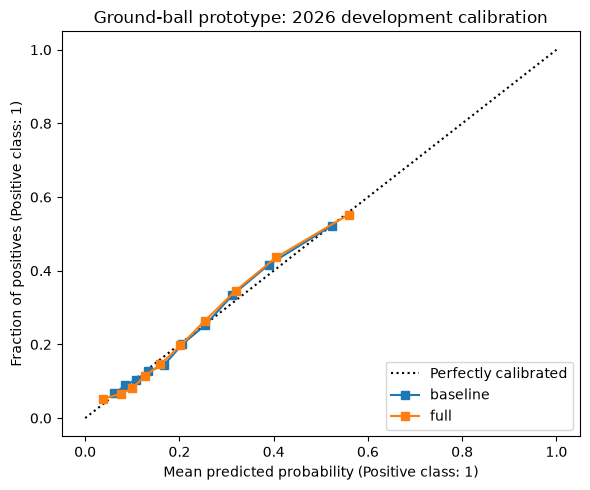

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["baseline", "full"]:
    CalibrationDisplay.from_predictions(
        test_data["single"], test_data[name], n_bins=10,
        strategy="quantile", name=name, ax=ax,
    )
ax.set_title("Ground-ball prototype: 2026 development calibration")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "xsimpson_v3_ground_ball_calibration.png", dpi=160)
plt.show()

The player table sums probabilities over **scored ground balls only**.
`actual_singles` uses those same plays. Coverage is scored / total ground balls;
missing-speed fraction is measured among scored plays. Players with no scoreable
ground balls remain in the table with zero coverage and an undefined missing-speed
fraction. Expected totals are not extrapolated to missing plays.

`placement_adjustment` is full minus baseline expected singles. The models are
fitted separately, so this comparison is not a causal estimate of placement or
proof that a player's placement effect will repeat.

In [18]:
evaluation_grounders = grounders.loc[grounders["season"].eq(TEST_YEAR)]
total_grounders = evaluation_grounders.groupby("batter").size()
results = test_data.groupby("batter").agg(
    scored_grounders=("single", "size"),
    actual_singles=("single", "sum"),
    baseline_expected_singles=("baseline", "sum"),
    full_expected_singles=("full", "sum"),
    missing_speed_fraction=("speed_missing", "mean"),
).reindex(total_grounders.index)
sum_columns = [
    "scored_grounders", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
]
results[sum_columns] = results[sum_columns].fillna(0)
results[["scored_grounders", "actual_singles"]] = results[
    ["scored_grounders", "actual_singles"]
].astype(int)
results["total_grounders"] = total_grounders
results["coverage"] = results["scored_grounders"] / results["total_grounders"]
results["placement_adjustment"] = (
    results["full_expected_singles"] - results["baseline_expected_singles"]
)
results = results[[
    "total_grounders", "scored_grounders", "coverage", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
    "placement_adjustment", "missing_speed_fraction",
]].sort_values("full_expected_singles", ascending=False)
assert results["scored_grounders"].sum() == len(test_data)
assert results["scored_grounders"].le(results["total_grounders"]).all()
print("Ground-ball singles prototype player table:")
display(results.head(20).round(3))

Ground-ball singles prototype player table:


,total_grounders,scored_grounders,coverage,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,missing_speed_fraction
batter,,,,,,,,
802415,331,328,0.991,98,67.073,74.583,7.510,0.0
672640,282,279,0.989,82,65.905,69.853,3.948,0.0
665487,258,258,1.000,75,65.609,68.574,2.965,0.0
650490,265,262,0.989,70,57.549,62.796,5.247,0.0
607208,227,226,0.996,60,60.105,62.397,2.292,0.0
663538,251,248,0.988,48,56.834,60.566,3.732,0.0
693304,234,232,0.991,73,57.936,60.236,2.301,0.0
666182,242,241,0.996,52,53.155,58.055,4.901,0.0
665489,227,227,1.000,55,55.936,56.367,0.431,0.0


In [19]:
print("Chandler Simpson: 2026 development evaluation; excluded from fitting.")
display(results.loc[results.index == SIMPSON_ID].round(3))
results.to_csv(RESULTS_PATH)
print("Saved:", RESULTS_PATH)

Chandler Simpson: 2026 development evaluation; excluded from fitting.


,total_grounders,scored_grounders,coverage,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,missing_speed_fraction
batter,,,,,,,,
802415,331,328,0.991,98,67.073,74.583,7.51,0.0


Saved: C:\Users\isaac\CodingProjects\SIMPSON\results\xsimpson_v3_ground_ball_results.csv


In [20]:
# Player names are display metadata, cached separately from model inputs.
player_names_path = DATA_DIR / f"player_names_{TEST_YEAR}.csv"
if DOWNLOAD and not player_names_path.is_file():
    response = requests.get(
        "https://statsapi.mlb.com/api/v1/sports/1/players",
        params={"season": TEST_YEAR},
        timeout=30,
    )
    response.raise_for_status()
    player_names = pd.DataFrame(response.json()["people"])
    player_names = player_names[["id", "fullName"]].rename(
        columns={"id": "batter", "fullName": "Name"}
    )
    player_names.to_csv(player_names_path, index=False)
player_names = load_csv(player_names_path, ["batter", "Name"])

In [21]:
# Build and export from saved CSVs; no fitted-model variables are needed.
leaderboard = pd.read_csv(RESULTS_DIR / "xsimpson_v3_ground_ball_results.csv")
player_names = pd.read_csv(
    DATA_DIR / f"player_names_{TEST_YEAR}.csv", usecols=["batter", "Name"],
)
leaderboard = leaderboard.merge(
    player_names, on="batter", how="left", validate="one_to_one",
)
if leaderboard["Name"].isna().any():
    raise ValueError("Player-name lookup is missing leaderboard players.")

season_plays = pd.read_csv(
    DATA_DIR / f"statcast_{TEST_YEAR}.csv",
    usecols=["game_type", "events", "game_pk", "at_bat_number", "batter"],
)
pa_counts = (
    season_plays.loc[season_plays["game_type"].eq("R") & season_plays["events"].notna()
        & season_plays["events"].ne("truncated_pa")]
    .drop_duplicates(["game_pk", "at_bat_number"])
    .groupby("batter").size()
)
leaderboard["PA"] = leaderboard["batter"].map(pa_counts)
leaderboard = leaderboard.sort_values("full_expected_singles", ascending=False)
leaderboard_columns = [
    "Name", "PA", "scored_grounders", "total_grounders", "actual_singles",
    "baseline_expected_singles", "full_expected_singles",
    "placement_adjustment", "coverage", "missing_speed_fraction", "batter",
]
leaderboard[leaderboard_columns].to_csv(
    RESULTS_DIR / "simpsonv3_leaderboard.csv", index=False,
)
display(leaderboard[leaderboard_columns].head(20).round(3))

,Name,PA,scored_grounders,total_grounders,actual_singles,baseline_expected_singles,full_expected_singles,placement_adjustment,coverage,missing_speed_fraction,batter
0,Chandler Simpson,612,328,331,98,67.073,74.583,7.510,0.991,0.0,802415
1,Otto Lopez,687,279,282,82,65.905,69.853,3.948,0.989,0.0,672640
2,Fernando Tatis Jr.,704,258,258,75,65.609,68.574,2.965,1.000,0.0,665487
3,Yandy Díaz,686,262,265,70,57.549,62.796,5.247,0.989,0.0,650490
4,Trea Turner,700,226,227,60,60.105,62.397,2.292,0.996,0.0,607208
5,Nico Hoerner,689,248,251,48,56.834,60.566,3.732,0.988,0.0,663538
6,Nick Gonzales,608,232,234,73,57.936,60.236,2.301,0.991,0.0,693304
7,Bo Bichette,696,241,242,52,53.155,58.055,4.901,0.996,0.0,666182
8,Vladimir Guerrero Jr.,609,227,227,55,55.936,56.367,0.431,1.000,0.0,665489
9,Junior Caminero,702,239,239,50,58.049,55.946,-2.103,1.000,0.0,691406


The ground-ball diagnostic remains unchanged. Its later-season results do not
establish repeatable player skill. The following batting-only extension adds
other fair-contact outcomes and walk/HBP accounting.

## Batting-only, contact-adjusted xSIMPSON

Fair-contact candidates use completed batted-ball event codes, including HR and
sacrifice contact. Catcher interference, walks/HBP, strikeouts, and truncated PA
are not contact. Caught foul-outs identified by `foul` in the play narrative are
excluded from fair contact but retain their PA and zero observed hit credit.
This text-based fair/foul check depends on consistent source descriptions.
[Statcast field definitions](https://baseballsavant.mlb.com/csv-docs) document
`events`, `des`, and the chart coordinates used here.

Classes are `no_hit`, `single`, `double`, `triple`, and `home_run`. Errors and
fielder's choices are `no_hit`: this initial convention gives no separate credit
for reaching on an error or forcing another runner out.

PA, unintentional walks, HBP, intentional walks, and observed hits are counted
from the complete PA data **before any contact-measurement filtering**. PA includes
sacrifices, interference, intentional walks, and HR; truncated PA are excluded.

### Verified PA ownership corrections

Four two-strike substitutions ended in strikeouts. OBR 9.15(b), official game logs,
and official play-by-play charge the PA/strikeout to the original batter. Apply the
four evidence-backed corrections to PA ownership only; keep physical Statcast
pitch records unchanged. Each terminal event is unique and present. The eight-player
audit records game, date, inning, at-bat, pitch, source URL, and before/after totals.
See `results/xsimpson_v3_pa_discrepancy_resolution.csv` and
[OBR 9.15(b)](https://img.mlbstatic.com/mlb-images/image/upload/mlb/ub08blsefk8wkkd2oemz.pdf#page=142).

| Date | Game | At-bat | PA/strikeout charged to | Terminal replacement |
|---|---:|---:|---|---|
| 2026-04-09 | 823565 | 3 | Brent Rooker | Lawrence Butler |
| 2026-05-23 | 824674 | 39 | Yordan Alvarez | Zach Dezenzo |
| 2026-06-06 | 824915 | 73 | Brandon Lowe | Jhostynxon Garcia |
| 2026-06-09 | 824023 | 51 | Sebastian Rivero | Logan O'Hoppe |

Each is a unique, present strikeout terminal event after a two-strike substitution.
All checked 2026 PA, hit, unintentional-walk, and HBP totals reconcile after repair.


In [22]:
OUTCOMES = ["no_hit", "single", "double", "triple", "home_run"]
HIT_EVENTS = OUTCOMES[1:]
FAIR_EVENTS = {
    *HIT_EVENTS, "field_out", "force_out", "grounded_into_double_play",
    "sac_fly", "sac_bunt", "field_error", "fielders_choice",
    "fielders_choice_out", "double_play", "sac_fly_double_play", "triple_play",
}
NONCONTACT_EVENTS = {
    "walk", "intent_walk", "hit_by_pitch", "strikeout",
    "strikeout_double_play", "catcher_interf",
}
unknown_events = set(plate_appearances["events"]) - FAIR_EVENTS - NONCONTACT_EVENTS
if unknown_events:
    raise ValueError(f"Review unrecognized PA events before accounting: {unknown_events}")
bat_pa = plate_appearances.copy()
bat_pa["statcast_terminal_batter"] = bat_pa["batter"]
pa_corrections = pd.read_csv(DATA_DIR / "pa_attribution_corrections.csv")
for correction in pa_corrections.itertuples(index=False):
    rows = (bat_pa["game_pk"].eq(correction.game_pk)
            & bat_pa["at_bat_number"].eq(correction.at_bat_number))
    assert rows.sum() == 1
    assert bat_pa.loc[rows, "events"].eq("strikeout").all()
    assert bat_pa.loc[rows, "batter"].eq(correction.statcast_batter).all()
    assert correction.strikes_at_substitution == 2
    bat_pa.loc[rows, "batter"] = correction.official_batter

In [23]:
candidates = bat_pa["events"].isin(FAIR_EVENTS)
assert bat_pa.loc[candidates, "des"].notna().all(), "Missing contact descriptions"
bat_pa["foul_out"] = (
    candidates & ~bat_pa["events"].isin(HIT_EVENTS)
    & bat_pa["des"].str.contains(r"\bfoul\b", case=False, na=False)
)
bat_pa["fair_contact"] = candidates & ~bat_pa["foul_out"]
bat_pa["unintentional_walk"] = bat_pa["events"].eq("walk").astype(int)
bat_pa["HBP"] = bat_pa["events"].eq("hit_by_pitch").astype(int)
bat_pa["intentional_walk"] = bat_pa["events"].eq("intent_walk").astype(int)
for outcome in HIT_EVENTS:
    bat_pa[f"observed_{outcome}"] = bat_pa["events"].eq(outcome).astype(int)
display(bat_pa.groupby("season").agg(
    PA=("events", "size"), fair_batted_balls=("fair_contact", "sum"),
    excluded_foul_outs=("foul_out", "sum"),
))

,PA,fair_batted_balls,excluded_foul_outs
season,,,
2024,182449,120662,3541
2025,182926,121407,3481
2026,183849,120973,3638


In [24]:
bat_eval_pa = bat_pa.loc[bat_pa["season"].eq(TEST_YEAR)]
bat_players = bat_eval_pa.groupby("batter").agg(
    PA=("events", "size"), unintentional_walks=("unintentional_walk", "sum"),
    HBP=("HBP", "sum"), intentional_walks=("intentional_walk", "sum"),
    fair_batted_balls=("fair_contact", "sum"), foul_outs=("foul_out", "sum"),
    observed_singles=("observed_single", "sum"),
    observed_doubles=("observed_double", "sum"),
    observed_triples=("observed_triple", "sum"),
    observed_home_runs=("observed_home_run", "sum"),
)
assert bat_players["PA"].gt(0).all()
assert bat_players["PA"].sum() == len(bat_eval_pa)
print("All evaluation PA counted before contact filtering:", len(bat_eval_pa))

All evaluation PA counted before contact filtering: 183849


### Independent season-total validation

Compare complete Statcast PA and observed hits with cached **2026 MLB season
hitting totals**, retrieved from the independent season-statistics endpoint:
[MLB season totals](https://statsapi.mlb.com/api/v1/stats?stats=season&group=hitting&season=2026&sportIds=1&playerPool=ALL&limit=2000).
This comparison does not use model predictions. Keep discrepancies visible rather
than silently replacing player attribution. The headline retains complete
Statcast PA; an official-denominator sensitivity is reported for flagged players.

In [25]:
season_validation = None
independent_path = DATA_DIR / f"mlb_batting_totals_{TEST_YEAR}.csv"
if independent_path.is_file():
    official_totals = load_csv(independent_path, [
        "season", "batter", "Name", "PA", "single", "double", "triple", "home_run",
        "walks", "intentional_walks", "HBP",
    ])
    assert official_totals["season"].eq(TEST_YEAR).all()
    assert official_totals["batter"].is_unique
    official_totals = official_totals.loc[official_totals["PA"].gt(0)].set_index("batter")
    official_totals["unintentional_walks"] = (
        official_totals["walks"] - official_totals["intentional_walks"]
    )
    total_fields = {
        "PA": "PA", "observed_singles": "single", "observed_doubles": "double",
        "observed_triples": "triple", "observed_home_runs": "home_run",
        "unintentional_walks": "unintentional_walks", "HBP": "HBP",
    }
    official_comparison = official_totals[list(total_fields.values())].rename(
        columns={v: f"official_{k}" for k, v in total_fields.items()}
    )
    season_validation = bat_players[list(total_fields)].join(
        official_comparison, how="outer", validate="one_to_one",
    )
    for local, source in total_fields.items():
        season_validation[f"{local}_difference"] = (
            season_validation[local] - season_validation[f"official_{local}"]
        )
    season_validation.to_csv(RESULTS_DIR / "xsimpson_v3_season_total_validation.csv")
else:
    print("Independent season-total source unavailable:", independent_path)

In [26]:
if season_validation is not None:
    difference_columns = [c for c in season_validation if c.endswith("_difference")]
    differences = season_validation[difference_columns]
    source_missing = season_validation[["PA", "official_PA"]].isna().any(axis=1)
    print("Players lacking a corresponding positive-PA season record:", source_missing.sum())
    display(pd.DataFrame({
        "players_with_difference": differences.ne(0).sum(),
        "net_difference": differences.sum(),
    }))
    print("PA discrepancies, Statcast minus independent source:")
    display(season_validation.loc[
        differences.ne(0).any(axis=1) | source_missing,
        ["PA", "official_PA", *difference_columns],
    ])
    print("Simpson independent-total check:")
    display(season_validation.loc[season_validation.index == SIMPSON_ID])

Players lacking a corresponding positive-PA season record: 0


,players_with_difference,net_difference
PA_difference,0,0
observed_singles_difference,0,0
observed_doubles_difference,0,0
observed_triples_difference,0,0
observed_home_runs_difference,0,0
unintentional_walks_difference,0,0
HBP_difference,0,0


PA discrepancies, Statcast minus independent source:


,PA,official_PA,PA_difference,observed_singles_difference,observed_doubles_difference,observed_triples_difference,observed_home_runs_difference,unintentional_walks_difference,HBP_difference
batter,,,,,,,,,


Simpson independent-total check:


,PA,observed_singles,observed_doubles,observed_triples,observed_home_runs,unintentional_walks,HBP,official_PA,official_observed_singles,official_observed_doubles,...,official_observed_home_runs,official_unintentional_walks,official_HBP,PA_difference,observed_singles_difference,observed_doubles_difference,observed_triples_difference,observed_home_runs_difference,unintentional_walks_difference,HBP_difference
batter,,,,,,,,,,,,,,,,,,,,,
802415,612,153,16,6,0,25,0,612,153,16,...,0,25,0,0,0,0,0,0,0,0


In [27]:
bat_contact = bat_pa.loc[bat_pa["fair_contact"]].copy()
bat_contact["outcome"] = bat_contact["events"].where(
    bat_contact["events"].isin(HIT_EVENTS), "no_hit"
)
bat_contact["outcome_code"] = pd.Categorical(
    bat_contact["outcome"], categories=OUTCOMES
).codes
bat_contact["bb_group"] = bat_contact["bb_type"].fillna("unknown")
bat_contact["spray_angle"] = np.degrees(np.arctan2(
    bat_contact["hc_x"] - 125.42, 198.27 - bat_contact["hc_y"]
))
bat_contact["left_handed"] = bat_contact["stand"].eq("L").astype(int)
bat_contact["speed_missing"] = bat_contact["sprint_speed"].isna().astype(int)
bat_contact["baseline_available"] = (
    np.isfinite(bat_contact[["launch_speed", "launch_angle"]]).all(axis=1)
    & bat_contact["stand"].isin(["L", "R"])
)
bat_contact["direction_available"] = (
    np.isfinite(bat_contact[["hc_x", "hc_y"]]).all(axis=1)
    & np.isfinite(bat_contact["spray_angle"])
)
bat_training_mask = (
    bat_contact["season"].isin(TRAIN_YEARS)
    & bat_contact["batter"].ne(SIMPSON_ID)
)
bat_training = bat_contact.loc[bat_training_mask].copy()
assert bat_training["batter"].ne(SIMPSON_ID).all()
display(pd.crosstab(bat_contact["season"], bat_contact["outcome"]))

outcome,double,home_run,no_hit,single,triple
season,,,,,
2024,7771,5453,80839,25902,697
2025,7745,5650,81269,26115,628
2026,7493,5575,81124,26110,671


Missing measurements have explicit routes. Both multinomial models fit the
same complete-measurement training rows. Their preprocessing fits training data
only. Fitting retains the training-play median speed and missing-speed indicator.
Headline inference below replaces missing speed with the unique-record reference
speed in both scenarios; the old median policy is retained for sensitivity analysis.

For evaluation and batting accounting, use the full model when EV/LA, handedness,
and direction are available. Use the baseline model when only direction is
missing. For missing EV/LA (or handedness), use the empirical five-outcome
frequencies for that batted-ball type in **all 2024-2025 training fair contact**,
excluding Simpson. Unknown types use overall training frequencies. No evaluation
outcomes enter these fallbacks, and no missing contact is silently assigned zero.

Metrics report both an identical complete-measurement sample and all fair contact
with these fallbacks. The latter compares the full scoring policy with baseline
scoring on the same plays. Calibration plots use the all-contact comparison.

In [28]:
bat_median_speed = bat_training["sprint_speed"].median()
assert pd.notna(bat_median_speed), "No training Sprint Speed matched"
bat_prior = bat_training["outcome"].value_counts(normalize=True).reindex(
    OUTCOMES, fill_value=0.0
)
bat_type_priors = pd.crosstab(
    bat_training["bb_group"], bat_training["outcome"], normalize="index"
).reindex(columns=OUTCOMES, fill_value=0.0)
assert np.isclose(bat_prior.sum(), 1)
assert np.allclose(bat_type_priors.sum(axis=1), 1)
bat_contact["sprint_speed"] = bat_contact["sprint_speed"].fillna(bat_median_speed)
bat_fit = bat_contact.loc[
    bat_training_mask & bat_contact["baseline_available"]
    & bat_contact["direction_available"]
].copy()
bat_eval = bat_contact.loc[bat_contact["season"].eq(TEST_YEAR)].copy()
assert len(bat_fit) and len(bat_eval)
assert bat_fit["batter"].ne(SIMPSON_ID).all()
assert set(bat_fit["outcome_code"]) == set(range(len(OUTCOMES)))
print("Training fair contact for fallback:", len(bat_training))
print("Identical multinomial fitting rows:", len(bat_fit))
print("2026 development fair-contact rows:", len(bat_eval))
print("Training-only speed replacement:", bat_median_speed)
display(bat_type_priors.round(5))

Training fair contact for fallback: 241696
Identical multinomial fitting rows: 240784
2026 development fair-contact rows: 120973
Training-only speed replacement: 27.5


outcome,no_hit,single,double,triple,home_run
bb_group,,,,,
fly_ball,0.74428,0.04486,0.04747,0.00712,0.15627
ground_ball,0.75355,0.22395,0.02123,0.00127,0.00000
line_drive,0.37685,0.42400,0.17111,0.01221,0.01582
popup,0.97958,0.01725,0.00300,0.00017,0.00000
unknown,1.00000,0.00000,0.00000,0.00000,0.00000


In [29]:
bat_models = {}
bat_baseline_columns = baseline_columns.copy()
bat_full_columns = bat_baseline_columns + ["spray_angle"]
for name, columns in [
    ("baseline", bat_baseline_columns), ("full", bat_full_columns),
]:
    # lbfgs fits the joint multinomial likelihood for the five outcome classes.
    bat_model = make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), LogisticRegression(solver="lbfgs", C=1.0, max_iter=2000),
    )
    bat_model.fit(bat_fit[columns], bat_fit["outcome_code"])
    assert np.array_equal(bat_model.classes_, np.arange(len(OUTCOMES)))
    assert bat_model.named_steps["standardscaler-1"].n_samples_seen_ == len(bat_fit)
    bat_models[name] = bat_model
print("Five-class models fitted on 2024-2025; Simpson excluded; no 2026 tuning.")

Five-class models fitted on 2024-2025; Simpson excluded; no 2026 tuning.


In [30]:
bat_fallback = pd.DataFrame(
    np.tile(bat_prior.to_numpy(), (len(bat_eval), 1)),
    index=bat_eval.index, columns=OUTCOMES,
)
for bb_type, probabilities in bat_type_priors.iterrows():
    bat_fallback.loc[bat_eval["bb_group"].eq(bb_type)] = probabilities.to_numpy()
bat_base_rows = bat_eval["baseline_available"]
bat_full_rows = bat_base_rows & bat_eval["direction_available"]
bat_baseline_prob = bat_fallback.copy()
bat_baseline_prob.loc[bat_base_rows] = bat_models["baseline"].predict_proba(
    bat_eval.loc[bat_base_rows, bat_baseline_columns]
)
bat_full_prob = bat_baseline_prob.copy()
bat_full_prob.loc[bat_full_rows] = bat_models["full"].predict_proba(
    bat_eval.loc[bat_full_rows, bat_full_columns]
)
bat_probabilities = {"baseline": bat_baseline_prob, "full": bat_full_prob}
for probabilities in bat_probabilities.values():
    assert probabilities.index.equals(bat_eval.index)
    assert np.isfinite(probabilities).all().all()
    assert probabilities.ge(0).all().all() and probabilities.le(1).all().all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-10)
bat_eval["prediction_source"] = np.select(
    [bat_full_rows, bat_base_rows],
    ["full_model", "baseline_direction_fallback"],
    default="training_contact_fallback",
)
print("Every fair-contact probability vector sums to one.")
display(pd.crosstab(bat_eval["bb_group"], bat_eval["prediction_source"]))

Every fair-contact probability vector sums to one.


prediction_source,baseline_direction_fallback,full_model,training_contact_fallback
bb_group,,,
fly_ball,48,32703,14
ground_ball,7,52310,479
line_drive,6,29358,11
popup,1,6033,3


### Speed association at fixed observed contact

Reference speed is the **unweighted mean of measured prior-season speeds across
unique (batter, play-season) records represented in full-model training**. A batter
represented in both training seasons contributes two records; contact volume does
not add weight. Missing speeds and Simpson are excluded.

Use the already fitted pipelines and change only the speed input. Keep contact,
direction, handedness, and the missing-speed indicator fixed. Full-model plays use
the full pipeline twice; direction fallbacks use the baseline pipeline twice;
empirical contact fallbacks are speed-independent in both scenarios.

For missing prior speed, put reference speed in **both** scenarios, giving zero
individualized speed conversion. This changes inference from the earlier
training-play median convention, without refitting preprocessing or coefficients.
The original median-policy predictions remain available for sensitivity analysis.
This decomposition is a **model-based association**, not a causal speed effect.

In [31]:
reference_records = bat_fit.loc[
    bat_fit["speed_missing"].eq(0), ["batter", "season", "sprint_speed"]
].copy()
assert reference_records["batter"].ne(SIMPSON_ID).all()
assert reference_records.groupby(["batter", "season"])["sprint_speed"].nunique().le(1).all()
reference_records = reference_records.drop_duplicates(["batter", "season"])
reference_speed = reference_records["sprint_speed"].mean()
assert np.isfinite(reference_speed)
reference_records.to_csv(RESULTS_DIR / "xsimpson_v3_reference_speed_records.csv", index=False)
print("Reference Sprint Speed:", reference_speed, "ft/s;")
print("Unique measured training batter-season records:", len(reference_records))
print("Training imputation remains:", bat_median_speed, "ft/s; no model refit.")
bat_previous_median_prob = bat_full_prob.copy()
missing_prior_speed = bat_eval["speed_missing"].eq(1)
bat_eval.loc[missing_prior_speed, "sprint_speed"] = reference_speed
player_speed_inputs = bat_eval[bat_full_columns].copy()
reference_speed_inputs = player_speed_inputs.copy()
reference_speed_inputs["sprint_speed"] = reference_speed
assert player_speed_inputs.drop(columns="sprint_speed").equals(
    reference_speed_inputs.drop(columns="sprint_speed")
)

Reference Sprint Speed: 27.384378211716342 ft/s;
Unique measured training batter-season records: 973
Training imputation remains: 27.5 ft/s; no model refit.


In [32]:
bat_speed_predictions = {}
bat_speed_baselines = {}
for scenario, features in [
    ("player_speed", player_speed_inputs), ("reference_speed", reference_speed_inputs),
]:
    probabilities = bat_fallback.copy()
    probabilities.loc[bat_base_rows] = bat_models["baseline"].predict_proba(
        features.loc[bat_base_rows, bat_baseline_columns]
    )
    bat_speed_baselines[scenario] = probabilities.copy()
    probabilities.loc[bat_full_rows] = bat_models["full"].predict_proba(
        features.loc[bat_full_rows, bat_full_columns]
    )
    assert np.isfinite(probabilities).all().all()
    assert probabilities.ge(0).all().all() and probabilities.le(1).all().all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-10)
    bat_speed_predictions[scenario] = probabilities
bat_baseline_prob = bat_speed_baselines["player_speed"]
bat_full_prob = bat_speed_predictions["player_speed"]
bat_reference_prob = bat_speed_predictions["reference_speed"]
bat_probabilities = {"baseline": bat_baseline_prob, "full": bat_full_prob}
assert np.allclose(
    bat_full_prob.loc[missing_prior_speed], bat_reference_prob.loc[missing_prior_speed]
)
assert np.allclose(
    bat_full_prob.loc[~missing_prior_speed], bat_previous_median_prob.loc[~missing_prior_speed]
)
print("Missing measured prior speed:", missing_prior_speed.sum(), "of", len(bat_eval),
      f"({missing_prior_speed.mean():.2%} of fair contact).")
print("All scenarios sum to one; all non-speed inputs held fixed.")

Missing measured prior speed: 15590 of 120973 (12.89% of fair contact).
All scenarios sum to one; all non-speed inputs held fixed.


In [33]:
bat_metric_rows = []
for scope, sample in [
    ("all_contact_with_fallbacks", bat_eval),
    ("complete_measurements", bat_eval.loc[bat_full_rows]),
]:
    groups = [("overall", sample)] + list(sample.groupby("bb_group"))
    for bb_type, group in groups:
        for name, probabilities in bat_probabilities.items():
            prediction = probabilities.loc[group.index]
            row = {
                "evaluation_set": scope, "bb_type": bb_type, "model": name,
                "rows": len(group), "log_loss": log_loss(
                    group["outcome_code"], prediction, labels=np.arange(len(OUTCOMES)),
                ),
            }
            for outcome in OUTCOMES:
                row[f"Brier_{outcome}"] = np.mean(
                    (group["outcome"].eq(outcome).astype(int) - prediction[outcome]) ** 2
                )
            row["Brier_total"] = sum(row[f"Brier_{outcome}"] for outcome in OUTCOMES)
            bat_metric_rows.append(row)
bat_metrics = pd.DataFrame(bat_metric_rows)
bat_metrics.to_csv(RESULTS_DIR / "xsimpson_v3_batting_metrics.csv", index=False)
display(bat_metrics.round(6))

,evaluation_set,bb_type,model,rows,log_loss,Brier_no_hit,Brier_single,Brier_double,Brier_triple,Brier_home_run,Brier_total
0,all_contact_with_fallbacks,overall,baseline,120973,0.724925,0.178144,0.153562,0.051574,0.005442,0.019809,0.408531
1,all_contact_with_fallbacks,overall,full,120973,0.692383,0.170446,0.151470,0.047800,0.005411,0.015678,0.390805
2,all_contact_with_fallbacks,fly_ball,baseline,32765,0.589316,0.125399,0.045452,0.042645,0.007572,0.063888,0.284956
3,all_contact_with_fallbacks,fly_ball,full,32765,0.530623,0.110799,0.046039,0.041533,0.007514,0.048385,0.254270
4,all_contact_with_fallbacks,ground_ball,baseline,52796,0.652960,0.178807,0.175716,0.019322,0.001192,0.000019,0.375056
5,all_contact_with_fallbacks,ground_ball,full,52796,0.641874,0.175483,0.172222,0.018621,0.001187,0.000029,0.367542
6,all_contact_with_fallbacks,line_drive,baseline,29375,1.129953,0.267570,0.261791,0.129288,0.011789,0.010284,0.680721
7,all_contact_with_fallbacks,line_drive,full,29375,1.080711,0.258095,0.258867,0.116092,0.011736,0.010547,0.655336
8,all_contact_with_fallbacks,popup,baseline,6037,0.119494,0.023488,0.019942,0.003954,0.000166,0.000000,0.047549
9,all_contact_with_fallbacks,popup,full,6037,0.122498,0.023636,0.019619,0.004692,0.000166,0.000000,0.048113


In [34]:
bat_comparison = bat_metrics.pivot(
    index=["evaluation_set", "bb_type", "rows"], columns="model",
    values=["log_loss", "Brier_total"] + [f"Brier_{c}" for c in OUTCOMES],
)
bat_changes = pd.DataFrame(index=bat_comparison.index)
for metric in ["log_loss", "Brier_total"] + [f"Brier_{c}" for c in OUTCOMES]:
    bat_changes[f"{metric}_full_minus_baseline"] = (
        bat_comparison[(metric, "full")] - bat_comparison[(metric, "baseline")]
    )
    bat_changes[f"{metric}_full_improves"] = (
        bat_changes[f"{metric}_full_minus_baseline"] < 0
    )
print("2026 development comparison: negative differences mean lower loss.")
display(bat_changes.round(6))
bat_changes.to_csv(RESULTS_DIR / "xsimpson_v3_batting_metric_comparison.csv")

2026 development comparison: negative differences mean lower loss.


log_loss_full_minus_baseline  \
evaluation_set             bb_type     rows                                   
all_contact_with_fallbacks fly_ball    32765                      -0.058693   
                           ground_ball 52796                      -0.011087   
                           line_drive  29375                      -0.049242   
                           overall     120973                     -0.032542   
                           popup       6037                        0.003004   
complete_measurements      fly_ball    32703                      -0.058804   
                           ground_ball 52310                      -0.011190   
                           line_drive  29358                      -0.049270   
                           overall     120404                     -0.032696   
                           popup       6033                        0.003006   

                                               log_loss_full_improves  \
evaluation_set             bb_type     rows                             
all_contact_with_fallbacks fly_ball    32765                     True   
                           ground_ball 52796                     True   
                           line_drive  29375                     True   
                           overall     120973                    True   
                           popup       6037                     False   
complete_measurements      fly_ball    32703                     True   
                           ground_ball 52310                     True   
                           line_drive  29358                     True   
                           overall     120404                    True   
                           popup       6033                     False   

                                               Brier_total_full_minus_baseline  \
evaluation_set             bb_type     rows                                      
all_contact_with_fallbacks fly_ball    32765                         -0.030685   
                           ground_ball 52796                         -0.007515   
                           line_drive  29375                         -0.025385   
                           overall     120973                        -0.017726   
                           popup       6037                           0.000564   
complete_measurements      fly_ball    32703                         -0.030743   
                           ground_ball 52310                         -0.007584   
                           line_drive  29358                         -0.025400   
                           overall     120404                        -0.017810   
                           popup       6033                           0.000564   

                                               Brier_total_full_improves  \
evaluation_set             bb_type     rows                                
all_contact_with_fallbacks fly_ball    32765                        True   
                           ground_ball 52796                        True   
                           line_drive  29375                        True   
                           overall     120973                       True   
                           popup       6037                        False   
complete_measurements      fly_ball    32703                        True   
                           ground_ball 52310                        True   
                           line_drive  29358                        True   
                           overall     120404                       True   
                           popup       6033                        False   

                                               Brier_no_hit_full_minus_baseline  \
evaluation_set             bb_type     rows                                       
all_contact_with_fallbacks fly_ball    32765                          -0.014600   
                           ground_ball 52796                          -0.0

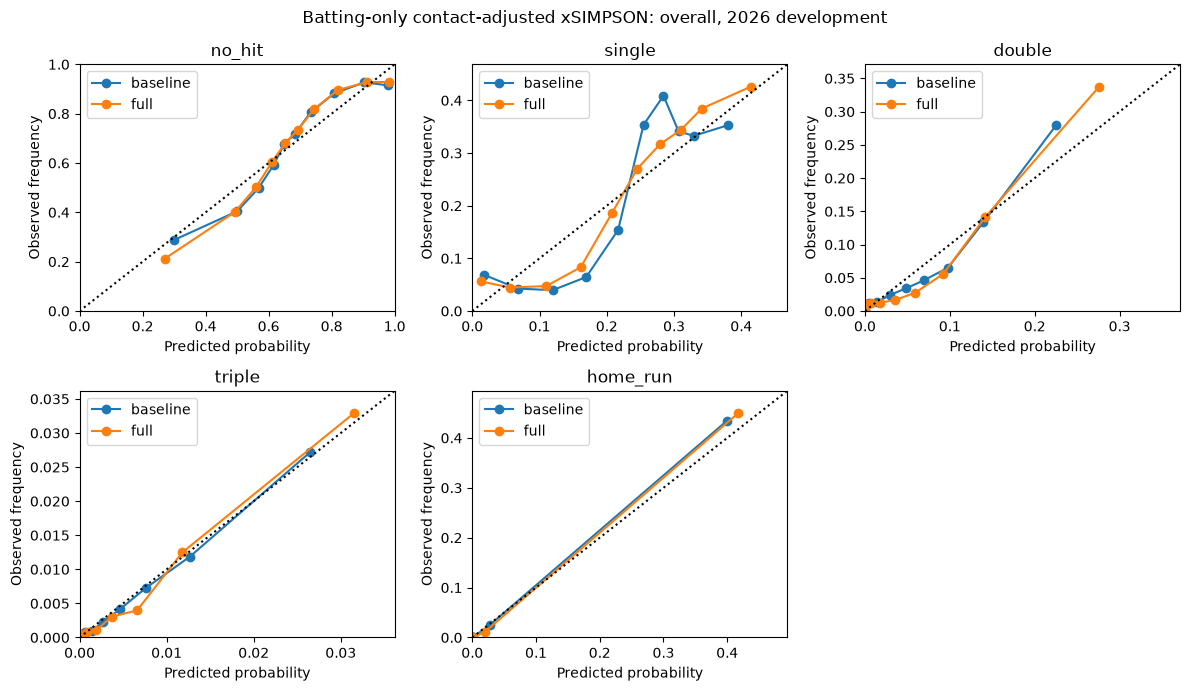

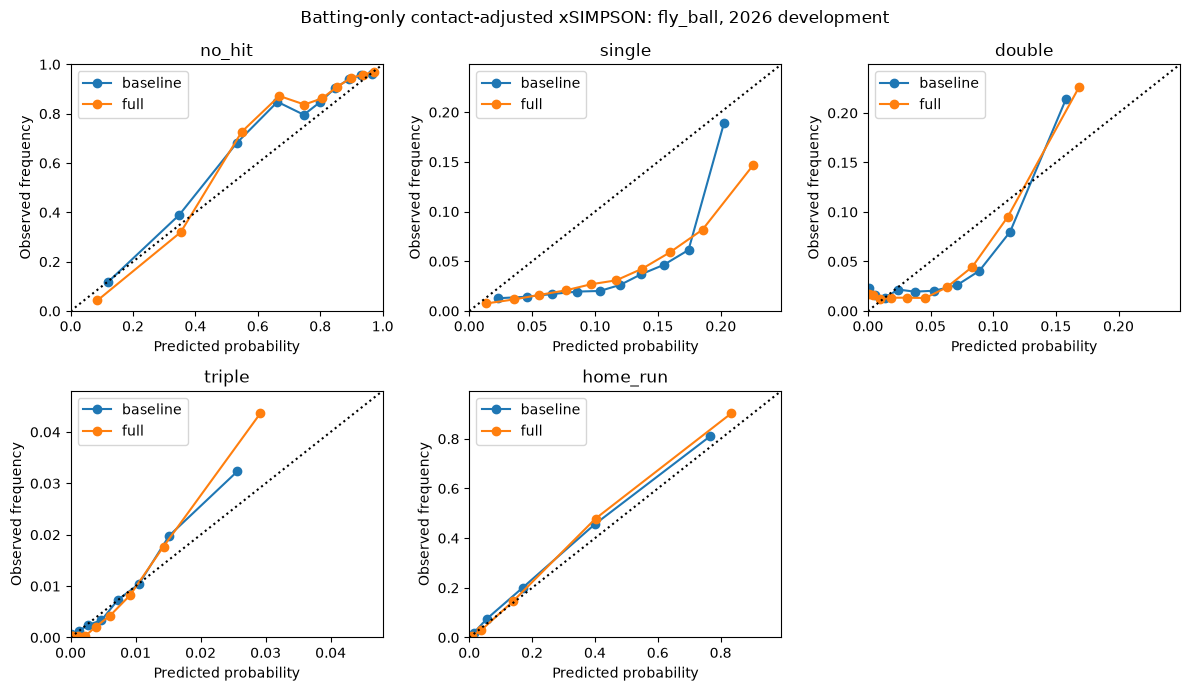

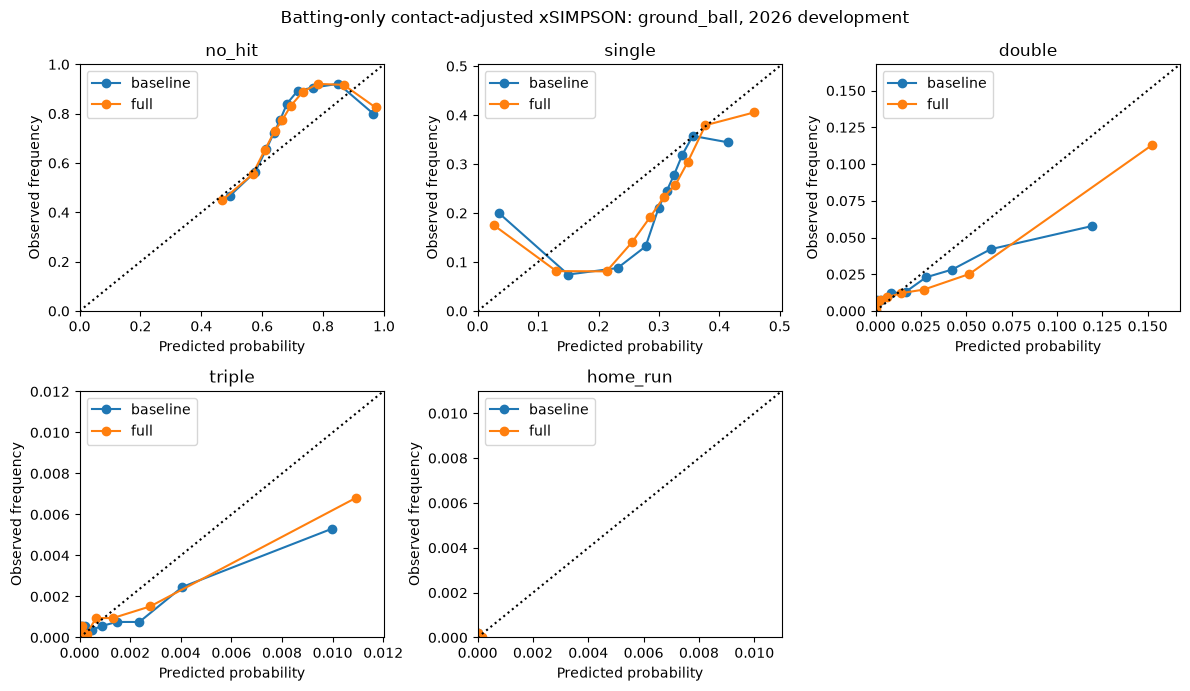

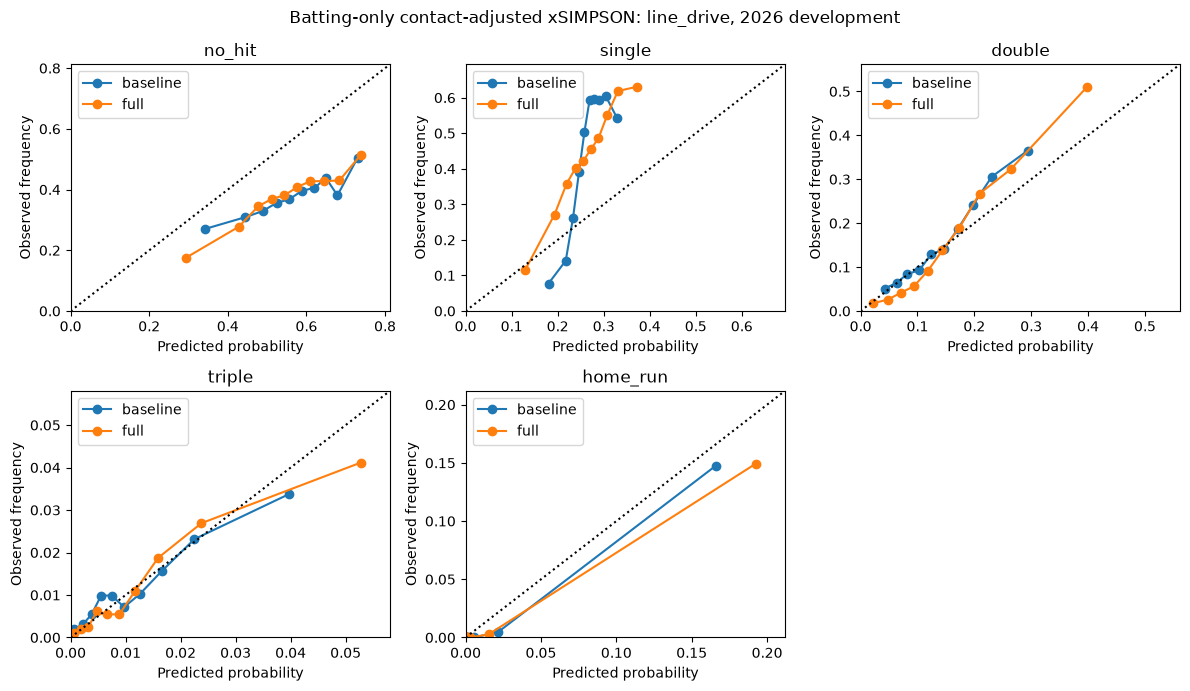

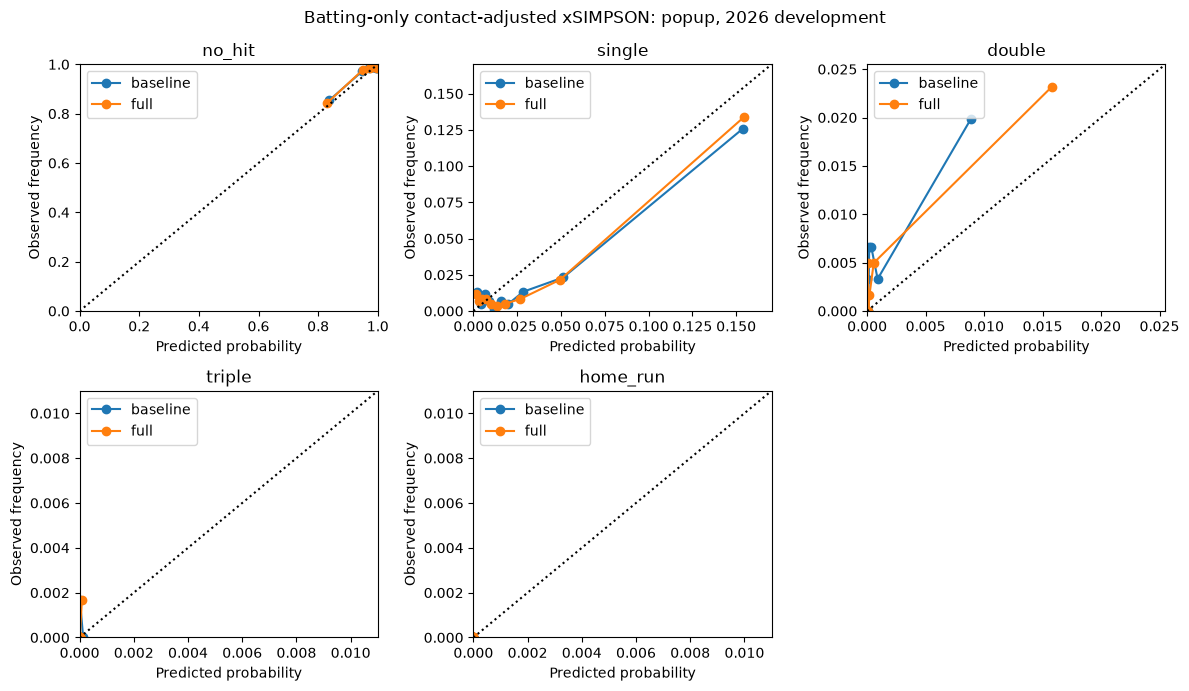

In [35]:
bat_calibration_rows = []
for group_name, group in [("overall", bat_eval)] + list(bat_eval.groupby("bb_group")):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    for outcome, ax in zip(OUTCOMES, axes.flat):
        axis_limit = 0.01
        for name, probabilities in bat_probabilities.items():
            observed, predicted = calibration_curve(
                group["outcome"].eq(outcome).astype(int),
                probabilities.loc[group.index, outcome], n_bins=10, strategy="quantile",
            )
            ax.plot(predicted, observed, marker="o", label=name)
            axis_limit = max(axis_limit, predicted.max(), observed.max())
            for bin_id, (p, y) in enumerate(zip(predicted, observed), start=1):
                bat_calibration_rows.append({
                    "bb_type": group_name, "outcome": outcome, "model": name,
                    "bin": bin_id, "mean_prediction": p, "observed_rate": y,
                })
        limit = min(1.0, axis_limit * 1.1)
        ax.plot([0, limit], [0, limit], "k:")
        ax.set(xlim=(0, limit), ylim=(0, limit), title=outcome,
               xlabel="Predicted probability", ylabel="Observed frequency")
        ax.legend()
    axes.flat[-1].axis("off")
    fig.suptitle(f"Batting-only contact-adjusted xSIMPSON: {group_name}, 2026 development")
    fig.tight_layout()
    fig.savefig(CHARTS_DIR / f"xsimpson_v3_batting_calibration_{group_name}.png", dpi=140)
    plt.show()
pd.DataFrame(bat_calibration_rows).to_csv(
    RESULTS_DIR / "xsimpson_v3_batting_calibration.csv", index=False,
)

## Event-credit accounting

Read the evaluation season's actual Guts columns. Each event credit is its wOBA
weight divided by `wOBAScale`. These are positive event credits under the requested
convention, not runs above average or a complete offensive run-value estimate.

`xSIMPSON_bat = (walk_credit * uBB + HBP_credit * HBP + expected_contact_credit) / PA`,
where expected contact credit sums `P(single)*single_credit + P(double)*double_credit
+ P(triple)*triple_credit` over **every fair batted ball**.

HR remains one of the five mutually exclusive model outcomes, but its credit is
zero in this non-HR accounting. Actual HR plays remain in both model data and PA;
they can receive expected non-HR hit credit through their predicted alternatives.
Intentional walks receive zero credit while retaining PA. Strikeouts, caught
foul-outs, interference, and other non-contact PA also retain the denominator.
The observed counterpart uses actual non-HR hits and the same walks/HBP, credits,
and denominator. Values are reported **per PA**, without multiplying by 100.

In [36]:
weight_columns = ["wBB", "wHBP", "w1B", "w2B", "w3B", "wHR"]
guts = load_csv(DATA_DIR / "fangraphs-guts-data.csv", [
    "Season", "wOBAScale", *weight_columns,
])
for column in ["Season", "wOBAScale", *weight_columns]:
    guts[column] = pd.to_numeric(guts[column], errors="raise")
season_weights = guts.loc[guts["Season"].eq(TEST_YEAR)]
if len(season_weights) != 1:
    raise ValueError(f"Require exactly one Guts weight row for {TEST_YEAR}.")
bat_weights = season_weights.iloc[0]
if not np.isfinite(bat_weights[["wOBAScale", *weight_columns]]).all():
    raise ValueError("Required Guts weights or scale are missing/nonfinite.")
if bat_weights["wOBAScale"] <= 0 or bat_weights[weight_columns].lt(0).any():
    raise ValueError("Require a positive wOBA scale and nonnegative event weights.")
bat_run_credits = (bat_weights[weight_columns] / bat_weights["wOBAScale"]).rename({
    "wBB": "walk", "wHBP": "HBP", "w1B": "single", "w2B": "double",
    "w3B": "triple", "wHR": "home_run",
})
print("Evaluation-season wOBA scale:", bat_weights["wOBAScale"])
display(bat_run_credits.rename("weight_divided_by_scale").to_frame())
NON_HR_HITS = ["single", "double", "triple"]

Evaluation-season wOBA scale: 1.23784


,weight_divided_by_scale
walk,0.564066
HBP,0.589066
single,0.719065
double,1.019065
triple,1.289068
home_run,1.655626


In [37]:
for outcome in HIT_EVENTS:
    bat_eval[f"expected_{outcome}"] = bat_full_prob[outcome]
bat_eval["expected_contact_credit"] = bat_full_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_eval["baseline_expected_contact_credit"] = bat_baseline_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_contact_totals = bat_eval.groupby("batter").agg(
    expected_singles=("expected_single", "sum"),
    expected_doubles=("expected_double", "sum"),
    expected_triples=("expected_triple", "sum"),
    expected_home_runs=("expected_home_run", "sum"),
    expected_contact_credit=("expected_contact_credit", "sum"),
    baseline_expected_contact_credit=("baseline_expected_contact_credit", "sum"),
)
# A zero here means no fair-contact plays, not unscored/missing contact.
bat_players = bat_players.join(bat_contact_totals).fillna(0)
assert bat_eval.groupby("batter").size().sum() == bat_players["fair_batted_balls"].sum()
bat_players["walk_credit"] = bat_players["unintentional_walks"] * bat_run_credits["walk"]
bat_players["HBP_credit"] = bat_players["HBP"] * bat_run_credits["HBP"]
bat_players["walk_HBP_credit"] = bat_players["walk_credit"] + bat_players["HBP_credit"]
bat_players["observed_contact_credit"] = sum(
    bat_players[f"observed_{outcome}s"] * bat_run_credits[outcome]
    for outcome in NON_HR_HITS
)
bat_players["xSIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["expected_contact_credit"]
) / bat_players["PA"]
bat_players["observed_SIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["observed_contact_credit"]
) / bat_players["PA"]
bat_players["baseline_xSIMPSON_bat"] = (
    bat_players["walk_HBP_credit"] + bat_players["baseline_expected_contact_credit"]
) / bat_players["PA"]

### Additive batting-credit decomposition

Contact Value is non-HR expected contact credit at reference speed. Speed
Conversion Value is player-speed credit minus reference-speed credit, retaining
negative values. Walk/HBP Value is unchanged. Their sum equals the current
expected batting credit and `PA * xSIMPSON_bat`.

Reported runs per 600 PA are these positive event-credit units scaled by
`600 / PA`; they are not runs above average. Missing-speed and empirical-fallback
plays have zero individualized speed conversion. All PA, including HR and IBB,
remain in the denominator, while their own event credit is excluded.

In [38]:
bat_eval["reference_contact_credit"] = bat_reference_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
bat_eval["speed_conversion_credit"] = (
    bat_eval["expected_contact_credit"] - bat_eval["reference_contact_credit"]
)
bat_eval["median_policy_contact_credit"] = bat_previous_median_prob[NON_HR_HITS].dot(
    bat_run_credits[NON_HR_HITS]
)
assert np.allclose(bat_eval.loc[missing_prior_speed, "speed_conversion_credit"], 0)
prior_fallback_rows = bat_eval["prediction_source"].eq("training_contact_fallback")
assert np.allclose(bat_eval.loc[prior_fallback_rows, "speed_conversion_credit"], 0)
components = bat_eval.groupby("batter").agg(
    contact_value=("reference_contact_credit", "sum"),
    speed_conversion_value=("speed_conversion_credit", "sum"),
    median_policy_contact_credit=("median_policy_contact_credit", "sum"),
    missing_prior_speed_contacts=("speed_missing", "sum"),
)
bat_players = bat_players.join(components).fillna(0)
bat_players["walk_HBP_value"] = bat_players["walk_HBP_credit"]
bat_players["expected_batting_credit"] = (
    bat_players["walk_HBP_value"] + bat_players["contact_value"]
    + bat_players["speed_conversion_value"]
)
assert np.allclose(bat_players["expected_batting_credit"], (
    bat_players["walk_HBP_credit"] + bat_players["expected_contact_credit"]
))
assert np.allclose(bat_players["expected_batting_credit"], bat_players["PA"] * bat_players["xSIMPSON_bat"])
for component, column in [
    ("walk_HBP_value", "walk_HBP_runs_per_600_PA"),
    ("contact_value", "contact_runs_per_600_PA"),
    ("speed_conversion_value", "speed_conversion_runs_per_600_PA"),
]:
    bat_players[column] = 600 * bat_players[component] / bat_players["PA"]
bat_players["batting_credit_per_600_PA"] = 600 * bat_players["xSIMPSON_bat"]
bat_players["reference_speed"] = reference_speed

In [39]:
bat_routes = pd.crosstab(bat_eval["batter"], bat_eval["prediction_source"]).reindex(
    index=bat_players.index,
    columns=["full_model", "baseline_direction_fallback", "training_contact_fallback"],
).fillna(0).astype(int)
assert bat_routes.sum(axis=1).eq(bat_players["fair_batted_balls"]).all()
contact_denominator = bat_players["fair_batted_balls"].where(
    bat_players["fair_batted_balls"].gt(0)
)
for route in bat_routes.columns:
    bat_players[f"{route}_contacts"] = bat_routes[route]
    bat_players[f"{route}_fraction"] = bat_routes[route] / contact_denominator
bat_players["contact_measurement_coverage"] = (
    bat_routes["full_model"] + bat_routes["baseline_direction_fallback"]
) / contact_denominator
bat_players["prediction_coverage"] = bat_routes.sum(axis=1) / contact_denominator
bat_eval["speed_replacement_used"] = (
    bat_eval["speed_missing"].eq(1) & bat_eval["baseline_available"]
)
bat_players["speed_replacement_fraction"] = (
    bat_eval.groupby("batter")["speed_replacement_used"].sum()
    .reindex(bat_players.index, fill_value=0) / contact_denominator
)
assert bat_players.loc[contact_denominator.notna(), "prediction_coverage"].eq(1).all()
assert np.isfinite(bat_players[["xSIMPSON_bat", "observed_SIMPSON_bat"]]).all().all()

In [40]:
bat_players["missing_prior_speed_fraction"] = (
    bat_players["missing_prior_speed_contacts"] / contact_denominator
)
bat_players["xSIMPSON_bat_previous_median"] = (
    bat_players["walk_HBP_credit"] + bat_players["median_policy_contact_credit"]
) / bat_players["PA"]
bat_players["missing_speed_policy_rate_change"] = (
    bat_players["xSIMPSON_bat"] - bat_players["xSIMPSON_bat_previous_median"]
)
if season_validation is not None:
    bat_players = bat_players.join(season_validation[["official_PA", "PA_difference"]])
    bat_players["official_PA_rate_sensitivity"] = (
        bat_players["expected_batting_credit"] / bat_players["official_PA"]
    )
sensitivity_rows = []
for label, probabilities, speed in [
    ("previous_training_median", bat_previous_median_prob, bat_median_speed),
    ("reference_speed_missing", bat_full_prob, reference_speed),
]:
    contact_credit = probabilities[NON_HR_HITS].dot(bat_run_credits[NON_HR_HITS]).sum()
    total_credit = bat_players["walk_HBP_credit"].sum() + contact_credit
    sensitivity_rows.append({
        "policy": label, "missing_speed_input": speed,
        "expected_batting_credit": total_credit,
        "aggregate_xSIMPSON_bat": total_credit / bat_players["PA"].sum(),
        "multiclass_log_loss": log_loss(
            bat_eval["outcome_code"], probabilities, labels=np.arange(len(OUTCOMES)),
        ),
    })
bat_sensitivity = pd.DataFrame(sensitivity_rows)
display(bat_sensitivity.round(8))
bat_sensitivity.to_csv(RESULTS_DIR / "xsimpson_v3_missing_speed_sensitivity.csv", index=False)
print("Players with negative speed conversion:", bat_players["speed_conversion_value"].lt(0).sum())
print("Missing-speed policy affects only inference; no 2026 tuning or refitting.")

,policy,missing_speed_input,expected_batting_credit,aggregate_xSIMPSON_bat,multiclass_log_loss
0,previous_training_median,27.500000,37363.109075,0.203227,0.692361
1,reference_speed_missing,27.384378,37410.675680,0.203486,0.692383


Players with negative speed conversion: 220
Missing-speed policy affects only inference; no 2026 tuning or refitting.


In [41]:
bat_players = bat_players.join(
    player_names.set_index("batter")[["Name"]], validate="one_to_one",
)
bat_players = bat_players[["Name"] + [c for c in bat_players if c != "Name"]]
bat_players = bat_players.sort_values("xSIMPSON_bat", ascending=False)
BATTING_DISPLAY_MIN_PA = 502  # Historical v2 threshold; CSV retains all players.
print("Batting-only, contact-adjusted xSIMPSON per PA; display PA >=", BATTING_DISPLAY_MIN_PA)
bat_display_columns = [
    "Name", "PA", "fair_batted_balls", "expected_singles", "expected_doubles",
    "expected_triples", "walk_HBP_credit", "expected_contact_credit",
    "xSIMPSON_bat", "observed_SIMPSON_bat", "contact_measurement_coverage",
    "walk_HBP_runs_per_600_PA", "contact_runs_per_600_PA",
    "speed_conversion_runs_per_600_PA", "missing_prior_speed_fraction",
    "baseline_direction_fallback_fraction", "training_contact_fallback_fraction",
]
display(bat_players.loc[
    bat_players["PA"].ge(BATTING_DISPLAY_MIN_PA), bat_display_columns
].head(20).round(4))
print("Chandler Simpson: excluded from both model fitting and all fallback estimates.")
display(bat_players.loc[bat_players.index == SIMPSON_ID, bat_display_columns].round(4))
bat_players.to_csv(RESULTS_DIR / "xsimpson_v3_batting_results.csv")
print("Saved batting-only results for", len(bat_players), "players.")
# Qualified display leaderboard; the results CSV retains every PA player.
bat_players.loc[
    bat_players["PA"].ge(BATTING_DISPLAY_MIN_PA), bat_display_columns
].to_csv(RESULTS_DIR / "xsimpson_v3_batting_leaderboard.csv")


Batting-only, contact-adjusted xSIMPSON per PA; display PA >= 502


,Name,PA,fair_batted_balls,expected_singles,expected_doubles,expected_triples,walk_HBP_credit,expected_contact_credit,xSIMPSON_bat,observed_SIMPSON_bat,contact_measurement_coverage,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,missing_prior_speed_fraction,baseline_direction_fallback_fraction,training_contact_fallback_fraction
batter,,,,,,,,,,,,,,,,,
803011,Sam Antonacci,557,398,94.2989,25.6918,3.9057,41.3377,99.0234,0.2520,0.2531,0.9950,44.5290,106.6679,0.0000,1.0,0.0000,0.0050
680757,Steven Kwan,637,476,115.7771,24.5679,1.6964,49.7378,110.4744,0.2515,0.2589,0.9979,46.8488,104.2569,-0.1993,0.0,0.0000,0.0021
672695,Geraldo Perdomo,680,488,112.2128,27.4142,2.3456,57.0956,111.6489,0.2482,0.2463,0.9959,50.3785,98.9540,-0.4403,0.0,0.0000,0.0041
800050,Chase DeLauter,559,404,90.0927,28.9496,4.0864,33.8689,99.5517,0.2387,0.2418,0.9950,36.3531,106.8534,0.0000,1.0,0.0000,0.0050
672515,Gabriel Moreno,549,394,91.5305,24.3996,1.3567,37.3533,92.4301,0.2364,0.2587,0.9975,40.8233,101.9043,-0.8878,0.0,0.0000,0.0025
693304,Nick Gonzales,608,451,113.2207,25.2804,3.1399,31.9127,111.2231,0.2354,0.2572,0.9956,31.4928,105.0309,4.7286,0.0,0.0000,0.0044
681198,TJ Rumfield,631,452,93.9098,27.1963,4.9916,46.5034,101.6766,0.2348,0.2593,0.9934,44.2187,96.6814,0.0000,1.0,0.0022,0.0066
663538,Nico Hoerner,689,569,137.2693,28.3377,2.9618,30.1455,131.4016,0.2345,0.2211,0.9930,26.2515,110.7555,3.6726,0.0,0.0000,0.0070
808982,Jung Hoo Lee,579,477,110.5924,29.9038,4.2747,19.9173,115.5074,0.2339,0.2270,0.9979,20.6397,117.0920,2.6048,0.0,0.0000,0.0021


Chandler Simpson: excluded from both model fitting and all fallback estimates.


,Name,PA,fair_batted_balls,expected_singles,expected_doubles,expected_triples,walk_HBP_credit,expected_contact_credit,xSIMPSON_bat,observed_SIMPSON_bat,contact_measurement_coverage,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,missing_prior_speed_fraction,baseline_direction_fallback_fraction,training_contact_fallback_fraction
batter,,,,,,,,,,,,,,,,,
802415,Chandler Simpson,612,530,136.0246,20.0044,2.9939,14.1016,122.0558,0.2225,0.2421,0.9943,13.8251,110.21,9.4525,0.0,0.0,0.0057


Saved batting-only results for 662 players.


## Comparison with v2 and remaining limits

The prior v2 notebook, retained in Git history, computes observed non-HR hit credit as
`(1B*w1B + 2B*w2B + 3B*w3B) / wOBAScale`, adds observed `BsR`, and reports
`100 * (hit_credit + BsR) / PA`. It omits walk and HBP credit. Its plus column
also depends on the selected baseline sample. This v3 score instead adds uBB/HBP
credit, replaces observed hits with contact-adjusted probabilities, omits BsR,
and reports per PA. Multiplying v3 by 100 changes its display scale but does not
make its accounting equivalent to v2. Neither the new rate nor its observed
counterpart is xSIMPSON+ or runs above average.

The saved table retains every evaluation player with PA, including players with
no fair contact. Coverage fractions are undefined for those with zero contact.
Expected HR counts are diagnostic only; no HR or intentional-walk credit enters
the score. Every fair contact has a prediction, including explicit fallbacks.

2026 remains a development evaluation. Improved prediction does not establish
repeatable player placement skill, and this contact-adjusted accounting is not a
prospective forecast. Fair/foul classification uses play text; direction is a
chart-coordinate approximation. Missing-contact fallback rates may not represent
a given player, and defensive positioning, parks, and other context remain
unmodeled. Baserunning and an untouched prospective evaluation remain later stages.

## Statcast xwOBA benchmark on shared scored plays

This benchmark includes HR and uses **raw wOBA units**, with no division by
`wOBAScale`. The cached `estimated_woba_using_speedangle` is used directly as a
scalar; no Statcast class probabilities are inferred. [Statcast field definitions](https://baseballsavant.mlb.com/csv-docs)
also identify the observed `woba_value` and denominator fields.

The supplied Statcast hit weights differ from this project's Guts weights.
For an aligned benchmark only, convert our probabilities with the unique observed
2026 Statcast hit weights (including HR), and compare both predictions with
Statcast's observed event weights. Retain full-model direct-scored fair contact
with available xwOBA and denominator 1. Exclude plays whose supplied observed
weight conflicts with the five-class convention, such as credited errors/choices;
report those exclusions explicitly. Local Guts weights remain unchanged for
batting accounting. A scalar xwOBA cannot be exactly reweighted to different
Guts weights without its underlying class probabilities.

Mean prediction error is predicted minus observed wOBA on identical shared plays;
it measures average bias. This is a batted-ball subset benchmark, not full-season
wOBA, a prospective validation, or proof that either model estimates causal skill.

In [42]:
benchmark_source = None
benchmark_path = DATA_DIR / f"statcast_expected_woba_{TEST_YEAR}.csv"
if benchmark_path.is_file():
    benchmark_source = load_csv(benchmark_path, [
        *pitch_keys, "batter", "events", "game_type",
        "estimated_woba_using_speedangle", "woba_value", "woba_denom",
    ])
    assert not benchmark_source.duplicated(pitch_keys).any()
    statcast_hit_weights = benchmark_source.loc[
        benchmark_source["game_type"].eq("R") & benchmark_source["events"].isin(HIT_EVENTS)
    ].groupby("events")["woba_value"].agg(["min", "max", "nunique"])
    assert set(statcast_hit_weights.index) == set(HIT_EVENTS)
    assert statcast_hit_weights["nunique"].eq(1).all()
    benchmark_weights = statcast_hit_weights["min"].reindex(OUTCOMES).fillna(0)
    benchmark_weight_audit = pd.DataFrame({
        "Statcast_raw_wOBA_weight": benchmark_weights,
        "Guts_raw_wOBA_weight": pd.Series({
            "no_hit": 0, "single": bat_weights["w1B"], "double": bat_weights["w2B"],
            "triple": bat_weights["w3B"], "home_run": bat_weights["wHR"],
        }),
    })
    display(benchmark_weight_audit)
    benchmark_weight_audit.to_csv(RESULTS_DIR / "xsimpson_v3_benchmark_weights.csv")
else:
    print("Statcast xwOBA benchmark unavailable:", benchmark_path)

,Statcast_raw_wOBA_weight,Guts_raw_wOBA_weight
no_hit,0.00,0.000000
single,0.90,0.890088
double,1.25,1.261440
triple,1.60,1.595660
home_run,2.00,2.049400


In [43]:
if benchmark_source is not None:
    benchmark_data = bat_eval[[*pitch_keys, "batter", "outcome", "bb_group"]].merge(
        benchmark_source.drop(columns=["events", "game_type"]),
        on=[*pitch_keys, "batter"], how="left", validate="one_to_one",
    )
    benchmark_data.index = bat_eval.index
    benchmark_data["class_observed_weight"] = benchmark_data["outcome"].map(benchmark_weights)
    benchmark_data["full_scored"] = bat_full_rows
    benchmark_data["xwOBA_available"] = np.isfinite(
        benchmark_data["estimated_woba_using_speedangle"]
    )
    benchmark_data["accounting_matches"] = np.isclose(
        benchmark_data["woba_value"], benchmark_data["class_observed_weight"]
    )
    benchmark_data["shared"] = (
        benchmark_data["full_scored"] & benchmark_data["xwOBA_available"]
        & benchmark_data["woba_denom"].eq(1) & benchmark_data["accounting_matches"]
    )
    benchmark_data["baseline_wOBA"] = bat_baseline_prob.dot(benchmark_weights)
    benchmark_data["full_wOBA"] = bat_full_prob.dot(benchmark_weights)
    print("Fair contact:", len(benchmark_data), "direct full-model rows:", bat_full_rows.sum())
    print("Available Statcast xwOBA:", benchmark_data["xwOBA_available"].sum())
    print("Observed-accounting conflicts among direct scored rows:", (
        benchmark_data["full_scored"] & ~benchmark_data["accounting_matches"]
    ).sum())
    print("Shared benchmark rows:", benchmark_data["shared"].sum())

Fair contact: 120973 direct full-model rows: 120404
Available Statcast xwOBA: 119752
Observed-accounting conflicts among direct scored rows: 2103
Shared benchmark rows: 118259


In [44]:
if benchmark_source is not None:
    benchmark_rows = []
    for bb_type, group in [("overall", benchmark_data)] + list(benchmark_data.groupby("bb_group")):
        shared = group.loc[group["shared"]]
        if shared.empty:
            continue
        for name, prediction_column in [
            ("baseline", "baseline_wOBA"), ("full", "full_wOBA"),
            ("Statcast_xwOBA", "estimated_woba_using_speedangle"),
        ]:
            error = shared[prediction_column] - shared["woba_value"]
            benchmark_rows.append({
                "bb_type": bb_type, "model": name, "shared_rows": len(shared),
                "fair_contact_rows": len(group), "direct_scored_rows": group["full_scored"].sum(),
                "coverage_of_direct_scored": len(shared) / group["full_scored"].sum(),
                "observed_mean_wOBA": shared["woba_value"].mean(),
                "predicted_mean_wOBA": shared[prediction_column].mean(),
                "mean_prediction_error": error.mean(), "RMSE": np.sqrt(np.mean(error ** 2)),
            })
    benchmark_results = pd.DataFrame(benchmark_rows)
    display(benchmark_results.round(6))
    benchmark_results.to_csv(RESULTS_DIR / "xsimpson_v3_statcast_xwoba_benchmark.csv", index=False)

,bb_type,model,shared_rows,fair_contact_rows,direct_scored_rows,coverage_of_direct_scored,observed_mean_wOBA,predicted_mean_wOBA,mean_prediction_error,RMSE
0,overall,baseline,118259,120973,120404,0.982185,0.379517,0.367991,-0.011526,0.472288
1,overall,full,118259,120973,120404,0.982185,0.379517,0.369093,-0.010424,0.447782
2,overall,Statcast_xwOBA,118259,120973,120404,0.982185,0.379517,0.373807,-0.005710,0.432637
3,fly_ball,baseline,32637,32765,32703,0.997982,0.422862,0.461395,0.038533,0.542597
4,fly_ball,full,32637,32765,32703,0.997982,0.422862,0.459801,0.036938,0.484531
5,fly_ball,Statcast_xwOBA,32637,32765,32703,0.997982,0.422862,0.415211,-0.007651,0.514615
6,ground_ball,baseline,50303,52796,52310,0.961633,0.238741,0.285608,0.046867,0.397207
7,ground_ball,full,50303,52796,52310,0.961633,0.238741,0.280218,0.041476,0.392744
8,ground_ball,Statcast_xwOBA,50303,52796,52310,0.961633,0.238741,0.231095,-0.007646,0.375251
9,line_drive,baseline,29312,29375,29358,0.998433,0.645643,0.474927,-0.170716,0.544821


The final headline uses the reference-speed missing-data policy consistently in
probabilities, credit, decomposition, and model evaluation. Training retains the
previous median imputation and all existing model settings. Negative speed
conversion is preserved. Four zero-contact players, if present, retain PA and
walk/HBP accounting, with undefined contact fractions.

Independent season totals can reveal player-attribution differences even when
league totals agree. Those discrepancies remain flagged, with an alternate
PA-denominator sensitivity, rather than silently moving event records. Statcast's
observed-event accounting and weight differences limit the benchmark to an
explicitly matched subset. All results remain a 2026 development evaluation;
model-based speed association is not a causal or prospective speed forecast.
Baserunning remains separate.

Missing-speed training rows were fitted at the old median with a missingness
indicator. Moving those rows to reference speed at inference can change predictions
through fitted interactions, even though individualized speed conversion is zero.
Treat the resulting headline sensitivity as an imputation-policy effect, not as
measured speed skill. The old-median headline is retained for comparison.

Inspect benchmark errors within batted-ball type as well as overall: offsetting
conditional biases can cancel in the aggregate. This diagnostic does not justify
retuning on the 2026 development sample.


## Recorded quadratic benchmark and one challenger

The pre-diagnostic notebook, metrics, and player tables were copied before edits.
Frozen fitted pipelines and keyed contact predictions below are written once to
`benchmarks/frozen_quadratic_benchmark`. Corrected PA attribution changes eight
player denominators but no fair-contact outcomes or original contact predictions.

Selection is confined to **2024 training and 2025 validation**, excluding Simpson
from both. Both candidates use the existing six full-model inputs and identical
complete-measurement rows. Training-only estimates provide median speed, reference
speed, and batted-ball-type/global fallbacks. Direction fallbacks use the same
2024 quadratic baseline. No new batted-ball-type input is added to either candidate.

One HistGradientBoosting configuration is fixed in advance: 150 iterations,
learning rate 0.05, 15 leaves, minimum leaf size 100, L2=1, no early stopping,
random seed 42. Select it only if 2025 complete-measurement log loss decreases,
macro class calibration ECE does not increase, and HR-inclusive event-value RMSE
does not increase. Otherwise retain quadratic. No 2026 or Simpson score enters
the decision. Calibration bins are derived from each model's 2024 predictions.

In [45]:
FROZEN_DIR = BENCHMARK_DIR
FROZEN_DIR.mkdir(parents=True, exist_ok=True)
frozen_model_path = FROZEN_DIR / "quadratic_models.joblib"
if not frozen_model_path.is_file():
    joblib.dump(bat_models, frozen_model_path)
frozen_models = joblib.load(frozen_model_path)
frozen_predictions = bat_eval[[*pitch_keys, "batter", "outcome", "bb_group"]].copy()
for name, probabilities in bat_probabilities.items():
    for outcome in OUTCOMES:
        frozen_predictions[f"{name}_{outcome}"] = probabilities[outcome]
frozen_prediction_path = FROZEN_DIR / "contact_predictions_2026.parquet"
if not frozen_prediction_path.is_file():
    frozen_predictions.to_parquet(frozen_prediction_path, index=False)
recorded = pd.read_parquet(frozen_prediction_path)
assert np.array_equal(recorded[pitch_keys].to_numpy(), frozen_predictions[pitch_keys].to_numpy())
for name in ("baseline", "full"):
    columns = [f"{name}_{outcome}" for outcome in OUTCOMES]
    assert np.allclose(recorded[columns], frozen_predictions[columns])
print("Frozen quadratic benchmark preserved; PA correction does not change contact predictions.")

Frozen quadratic benchmark preserved; PA correction does not change contact predictions.

In [46]:
def contact_probabilities(full_model, baseline_model, frame, prior, type_priors):
    probabilities = pd.DataFrame(
        np.tile(prior.to_numpy(), (len(frame), 1)), index=frame.index, columns=OUTCOMES,
    )
    for bb_type, values in type_priors.iterrows():
        probabilities.loc[frame["bb_group"].eq(bb_type)] = values.to_numpy()
    base_rows = frame["baseline_available"]
    full_rows = base_rows & frame["direction_available"]
    if base_rows.any():
        probabilities.loc[base_rows] = baseline_model.predict_proba(
            frame.loc[base_rows, bat_baseline_columns]
        )
    if full_rows.any():
        probabilities.loc[full_rows] = full_model.predict_proba(
            frame.loc[full_rows, bat_full_columns]
        )
    assert np.isfinite(probabilities).all().all()
    assert np.allclose(probabilities.sum(axis=1), 1)
    return probabilities

HGB_SETTINGS = dict(
    learning_rate=0.05, max_iter=150, max_leaf_nodes=15,
    min_samples_leaf=100, l2_regularization=1.0,
    early_stopping=False, random_state=42,
)

In [47]:
def outcome_metrics(frame, probabilities, weights):
    actual = frame["outcome"].map(weights)
    predicted = probabilities.dot(weights)
    result = {
        "rows": len(frame),
        "log_loss": log_loss(frame["outcome_code"], probabilities, labels=np.arange(5)),
        "event_value_RMSE": np.sqrt(np.mean((predicted - actual) ** 2)),
        "wOBA_error_predicted_minus_observed": (predicted - actual).mean(),
    }
    for outcome in OUTCOMES:
        actual_frequency = frame["outcome"].eq(outcome).mean()
        result[f"actual_{outcome}"] = actual_frequency
        result[f"predicted_{outcome}"] = probabilities[outcome].mean()
        result[f"Brier_{outcome}"] = np.mean(
            (frame["outcome"].eq(outcome).astype(int) - probabilities[outcome]) ** 2
        )
    return result

def calibration_audit(training_probabilities, frame, probabilities):
    records = []
    for outcome in OUTCOMES:
        edges = np.unique(np.r_[
            -np.inf, training_probabilities[outcome].quantile(np.arange(0.1, 1, 0.1)), np.inf,
        ])
        bins = pd.cut(probabilities[outcome], edges)
        values = pd.DataFrame({
            "bin": bins, "predicted": probabilities[outcome],
            "actual": frame["outcome"].eq(outcome).astype(int),
        }).groupby("bin", observed=True).agg(
            rows=("actual", "size"), predicted=("predicted", "mean"), actual=("actual", "mean"),
        )
        values["outcome"] = outcome
        records.append(values.reset_index(drop=True))
    table = pd.concat(records, ignore_index=True)
    ece = (table["rows"] * (table["actual"] - table["predicted"]).abs()).sum() / (5 * len(frame))
    return ece, table

In [48]:
selection_train = bat_contact.loc[
    bat_contact["season"].eq(2024) & bat_contact["batter"].ne(SIMPSON_ID)
].copy()
selection_eval = bat_contact.loc[
    bat_contact["season"].eq(2025) & bat_contact["batter"].ne(SIMPSON_ID)
].copy()
selection_median = selection_train.loc[
    selection_train["speed_missing"].eq(0), "sprint_speed"
].median()
selection_fit_rows = selection_train["baseline_available"] & selection_train["direction_available"]
selection_fit = selection_train.loc[selection_fit_rows].copy()
selection_reference = selection_fit.loc[
    selection_fit["speed_missing"].eq(0), ["batter", "season", "sprint_speed"]
].drop_duplicates(["batter", "season"])["sprint_speed"].mean()
selection_fit.loc[selection_fit["speed_missing"].eq(1), "sprint_speed"] = selection_median
selection_eval.loc[selection_eval["speed_missing"].eq(1), "sprint_speed"] = selection_reference
selection_prior = selection_train["outcome"].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0)
selection_type_priors = pd.crosstab(
    selection_train["bb_group"], selection_train["outcome"], normalize="index"
).reindex(columns=OUTCOMES, fill_value=0)
selection_shared = selection_eval["baseline_available"] & selection_eval["direction_available"]
validation_complete = selection_eval.loc[selection_shared]
validation_weights = guts.loc[guts["Season"].eq(2025)].iloc[0]
assert np.isfinite(validation_weights[weight_columns]).all()
validation_event_weights = pd.Series({
    "no_hit": 0, "single": validation_weights["w1B"], "double": validation_weights["w2B"],
    "triple": validation_weights["w3B"], "home_run": validation_weights["wHR"],
})
print("Selection uses only", len(selection_fit), "2024 fitting rows and",
      len(validation_complete), "2025 shared validation rows; Simpson excluded.")

Selection uses only 120240 2024 fitting rows and 120544 2025 shared validation rows; Simpson excluded.


In [49]:
selection_quadratic = {}
for name, columns in [("baseline", bat_baseline_columns), ("full", bat_full_columns)]:
    fitted = make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), LogisticRegression(C=1.0, max_iter=2000),
    )
    fitted.fit(selection_fit[columns], selection_fit["outcome_code"])
    selection_quadratic[name] = fitted
selection_hgb = HistGradientBoostingClassifier(**HGB_SETTINGS)
with threadpool_limits(limits=4):
    selection_hgb.fit(selection_fit[bat_full_columns], selection_fit["outcome_code"])
selection_candidates = {
    "quadratic": selection_quadratic["full"], "hist_gradient_boosting": selection_hgb,
}
selection_predictions = {}
selection_rows = []
selection_calibrations = []
for name, candidate in selection_candidates.items():
    probabilities = contact_probabilities(
        candidate, selection_quadratic["baseline"], selection_eval,
        selection_prior, selection_type_priors,
    )
    selection_predictions[name] = probabilities
    train_prob = pd.DataFrame(candidate.predict_proba(selection_fit[bat_full_columns]),
                              index=selection_fit.index, columns=OUTCOMES)
    ece, calibration = calibration_audit(
        train_prob, validation_complete, probabilities.loc[validation_complete.index],
    )
    calibration["model"] = name
    selection_calibrations.append(calibration)
    for sample_name, frame in [("complete_measurements", validation_complete),
                               ("all_contact_with_fallbacks", selection_eval)]:
        row = outcome_metrics(frame, probabilities.loc[frame.index], validation_event_weights)
        sample_ece, _ = calibration_audit(train_prob, frame, probabilities.loc[frame.index])
        row.update(model=name, evaluation_set=sample_name, calibration_ECE=sample_ece)
        selection_rows.append(row)
selection_metrics = pd.DataFrame(selection_rows)
selection_metrics.to_csv(RESULTS_DIR / "xsimpson_v3_validation_2025.csv", index=False)
display(selection_metrics.round(6))

,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed,actual_no_hit,predicted_no_hit,Brier_no_hit,actual_single,predicted_single,Brier_single,...,Brier_double,actual_triple,predicted_triple,Brier_triple,actual_home_run,predicted_home_run,Brier_home_run,model,evaluation_set,calibration_ECE
0,120544,0.697842,0.447695,0.010118,0.668909,0.662962,0.171364,0.215266,0.214767,0.151358,...,0.049367,0.005177,0.006314,0.005069,0.046589,0.049275,0.016269,quadratic,complete_measurements,0.018950
1,121034,0.696968,0.447347,0.010415,0.669382,0.663081,0.171190,0.214907,0.214752,0.151218,...,0.049221,0.005164,0.006297,0.005057,0.046681,0.049346,0.016223,quadratic,all_contact_with_fallbacks,0.019013
2,120544,0.464055,0.374718,0.009480,0.668909,0.663057,0.111990,0.215266,0.216217,0.093539,...,0.037774,0.005177,0.005907,0.004980,0.046589,0.049469,0.013817,hist_gradient_boosting,complete_measurements,0.007930
3,121034,0.464127,0.374627,0.009780,0.669382,0.663176,0.112057,0.214907,0.216195,0.093632,...,0.037675,0.005164,0.005891,0.004968,0.046681,0.049538,0.013781,hist_gradient_boosting,all_contact_with_fallbacks,0.008054


Selected using 2025 only: hist_gradient_boosting


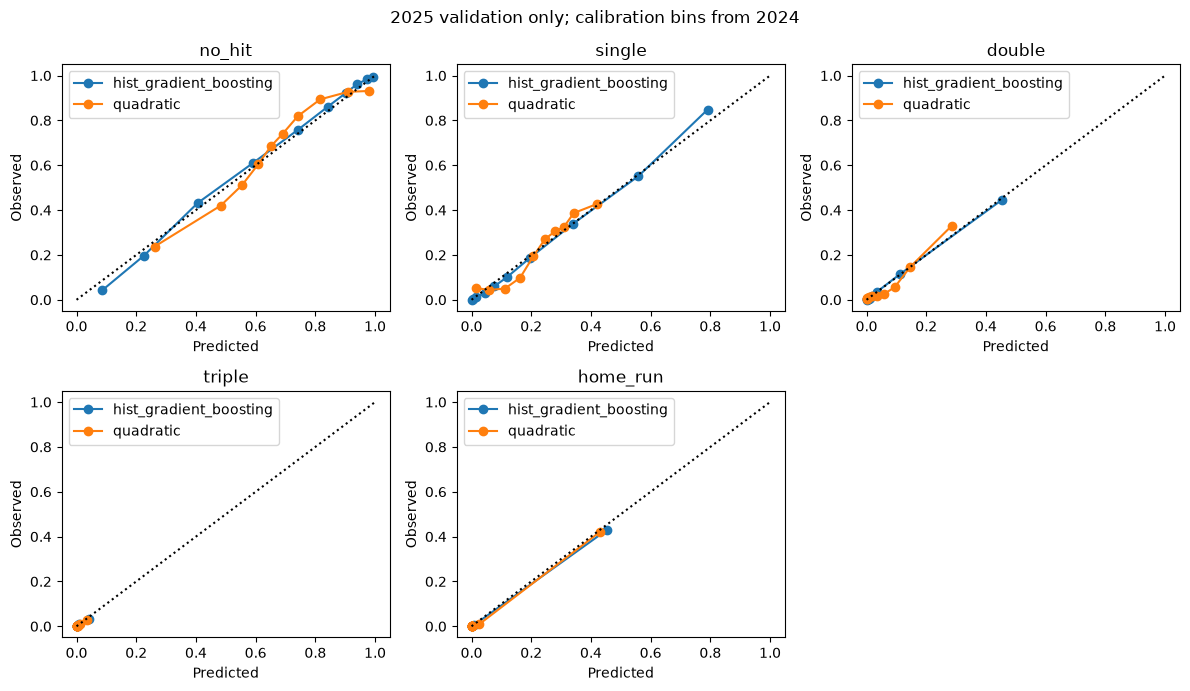

In [50]:
selection_scores = selection_metrics.loc[
    selection_metrics["evaluation_set"].eq("complete_measurements")
].set_index("model")
quadratic_score = selection_scores.loc["quadratic"]
challenger_score = selection_scores.loc["hist_gradient_boosting"]
challenger_passes = (
    challenger_score["log_loss"] < quadratic_score["log_loss"]
    and challenger_score["calibration_ECE"] <= quadratic_score["calibration_ECE"]
    and challenger_score["event_value_RMSE"] <= quadratic_score["event_value_RMSE"]
)
selected_name = "hist_gradient_boosting" if challenger_passes else "quadratic"
print("Selected using 2025 only:", selected_name)
pd.DataFrame([{
    "selected_model": selected_name, "validation_season": 2025, "training_season": 2024,
    "rule": "lower log loss; no worse ECE and event-value RMSE", "Simpson_excluded": True,
}]).to_csv(RESULTS_DIR / "xsimpson_v3_model_selection.csv", index=False)
selection_calibration = pd.concat(selection_calibrations, ignore_index=True)
selection_calibration.to_csv(RESULTS_DIR / "xsimpson_v3_validation_calibration_2025.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for outcome, ax in zip(OUTCOMES, axes.flat):
    for name, group in selection_calibration.loc[
        selection_calibration["outcome"].eq(outcome)
    ].groupby("model"):
        ax.plot(group["predicted"], group["actual"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], "k:")
    ax.set(title=outcome, xlabel="Predicted", ylabel="Observed")
    ax.legend()
axes.flat[-1].axis("off")
fig.suptitle("2025 validation only; calibration bins from 2024")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "xsimpson_v3_validation_calibration_2025.png", dpi=140)
plt.show()

In [51]:
if selected_name == "hist_gradient_boosting":
    selected_model = HistGradientBoostingClassifier(**HGB_SETTINGS)
    with threadpool_limits(limits=4):
        selected_model.fit(bat_fit[bat_full_columns], bat_fit["outcome_code"])
else:
    selected_model = frozen_models["full"]
assert bat_fit["batter"].ne(SIMPSON_ID).all()
selected_prob = contact_probabilities(
    selected_model, frozen_models["baseline"], bat_eval, bat_prior, bat_type_priors,
)
selected_reference_frame = bat_eval.copy()
selected_reference_frame["sprint_speed"] = reference_speed
assert bat_eval[bat_full_columns].drop(columns="sprint_speed").equals(
    selected_reference_frame[bat_full_columns].drop(columns="sprint_speed")
)
selected_reference_prob = contact_probabilities(
    selected_model, frozen_models["baseline"], selected_reference_frame,
    bat_prior, bat_type_priors,
)
assert np.allclose(selected_prob.loc[missing_prior_speed], selected_reference_prob.loc[missing_prior_speed])
joblib.dump({"model": selected_model, "baseline_fallback": frozen_models["baseline"],
             "features": bat_full_columns, "reference_speed": reference_speed,
             "prior": bat_prior, "type_priors": bat_type_priors},
            MODELS_DIR / "xsimpson_v3_selected_model.joblib")
print("Refit selected approach on 2024-2025, same settings; 2026 is development evaluation.")

Refit selected approach on 2024-2025, same settings; 2026 is development evaluation.


## 2026 development diagnostics on identical plays

Use predicted-minus-observed for every signed error column. The three-way
baseline/full/Statcast comparison uses the same previously audited shared-play
mask, HR-inclusive raw Statcast event weights, and observed-accounting convention.
Statcast supplies a scalar xwOBA, so its multiclass log loss and predicted outcome
frequencies are **unavailable**, not inferred. Actual outcome frequencies and wOBA
error/RMSE use exactly the same rows for every model.

Additional all-fair-contact model metrics use the actual 2026 Guts raw weights
including HR. Coverage and excluded-accounting counts are reported separately;
exclusion reasons can overlap. The selected model was chosen before this 2026
comparison, using 2025 only.

In [52]:
quadratic_players = bat_players.copy()
development_probabilities = {
    "quadratic_baseline": bat_baseline_prob,
    "quadratic_full": bat_full_prob,
    f"selected_{selected_name}": selected_prob,
}
development_weights = pd.Series({
    "no_hit": 0, "single": bat_weights["w1B"], "double": bat_weights["w2B"],
    "triple": bat_weights["w3B"], "home_run": bat_weights["wHR"],
})
development_rows = []
for bb_type, frame in [("overall", bat_eval)] + list(bat_eval.groupby("bb_group")):
    for name, probabilities in development_probabilities.items():
        row = outcome_metrics(frame, probabilities.loc[frame.index], development_weights)
        row.update(model=name, bb_type=bb_type, evaluation="2026_development",
                   weight_convention="2026_Guts_raw_including_HR")
        development_rows.append(row)
development_metrics = pd.DataFrame(development_rows)
development_metrics.to_csv(RESULTS_DIR / "xsimpson_v3_model_development_2026.csv", index=False)
display(development_metrics.loc[development_metrics["bb_type"].eq("overall")].round(6))

,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed,actual_no_hit,predicted_no_hit,Brier_no_hit,actual_single,predicted_single,Brier_single,...,actual_triple,predicted_triple,Brier_triple,actual_home_run,predicted_home_run,Brier_home_run,model,bb_type,evaluation,weight_convention
0,120973,0.724925,0.471909,-0.006280,0.670596,0.673963,0.178144,0.215833,0.214562,0.153562,...,0.005547,0.005624,0.005442,0.046085,0.042873,0.019809,quadratic_baseline,overall,2026_development,2026_Guts_raw_including_HR
1,120973,0.692383,0.447081,-0.005080,0.670596,0.673793,0.170446,0.215833,0.213712,0.151470,...,0.005547,0.005662,0.005411,0.046085,0.043707,0.015678,quadratic_full,overall,2026_development,2026_Guts_raw_including_HR
2,120973,0.456034,0.373988,-0.005976,0.670596,0.674103,0.110694,0.215833,0.214580,0.092573,...,0.005547,0.005249,0.005316,0.046085,0.043652,0.013476,selected_hist_gradient_boosting,overall,2026_development,2026_Guts_raw_including_HR


In [53]:
same_play_rows = []
shared_frame = bat_eval.loc[benchmark_data["shared"]]
for bb_type, frame in [("overall", shared_frame)] + list(shared_frame.groupby("bb_group")):
    for name, probabilities in development_probabilities.items():
        row = outcome_metrics(frame, probabilities.loc[frame.index], benchmark_weights)
        row.update(model=name, bb_type=bb_type, evaluation="2026_development_shared",
                   outcome_probabilities_available=True)
        same_play_rows.append(row)
    observed = benchmark_data.loc[frame.index, "woba_value"]
    predicted = benchmark_data.loc[frame.index, "estimated_woba_using_speedangle"]
    row = {
        "model": "Statcast_xwOBA", "bb_type": bb_type, "rows": len(frame),
        "evaluation": "2026_development_shared", "outcome_probabilities_available": False,
        "log_loss": np.nan,
        "event_value_RMSE": np.sqrt(np.mean((predicted - observed) ** 2)),
        "wOBA_error_predicted_minus_observed": (predicted - observed).mean(),
    }
    for outcome in OUTCOMES:
        row[f"actual_{outcome}"] = frame["outcome"].eq(outcome).mean()
        row[f"predicted_{outcome}"] = np.nan
    same_play_rows.append(row)
same_play_diagnostics = pd.DataFrame(same_play_rows)
same_play_diagnostics.to_csv(RESULTS_DIR / "xsimpson_v3_same_play_diagnostics.csv", index=False)
display(same_play_diagnostics.round(6))

,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed,actual_no_hit,predicted_no_hit,Brier_no_hit,actual_single,predicted_single,Brier_single,...,actual_triple,predicted_triple,Brier_triple,actual_home_run,predicted_home_run,Brier_home_run,model,bb_type,evaluation,outcome_probabilities_available
0,118259,0.731591,0.472288,-0.011526,0.664364,0.673473,0.179214,0.220026,0.213505,0.154516,...,0.005674,0.005719,0.005566,0.046660,0.043411,0.020179,quadratic_baseline,overall,2026_development_shared,True
1,118259,0.697299,0.447782,-0.010424,0.664364,0.673396,0.171149,0.220026,0.212520,0.152157,...,0.005674,0.005764,0.005535,0.046660,0.044270,0.015960,quadratic_full,overall,2026_development_shared,True
2,118259,0.458800,0.373923,-0.009939,0.664364,0.672225,0.111097,0.220026,0.214762,0.092799,...,0.005674,0.005342,0.005437,0.046660,0.044209,0.013709,selected_hist_gradient_boosting,overall,2026_development_shared,True
3,118259,NaN,0.432637,-0.005710,0.664364,NaN,NaN,0.220026,NaN,NaN,...,0.005674,NaN,NaN,0.046660,NaN,NaN,Statcast_xwOBA,overall,2026_development_shared,False
4,32637,0.590115,0.542597,0.038533,0.744676,0.685440,0.125528,0.044489,0.111393,0.045573,...,0.007783,0.006790,0.007601,0.155406,0.139741,0.063919,quadratic_baseline,fly_ball,2026_development_shared,True
5,32637,0.531292,0.484531,0.036938,0.744676,0.687904,0.110898,0.044489,0.110423,0.046160,...,0.007783,0.006663,0.007544,0.155406,0.141329,0.048378,quadratic_full,fly_ball,2026_development_shared,True
6,32637,0.339370,0.414255,-0.022266,0.744676,0.757201,0.067491,0.044489,0.043643,0.018779,...,0.007783,0.006527,0.007452,0.155406,0.146785,0.041376,selected_hist_gradient_boosting,fly_ball,2026_development_shared,True
7,32637,NaN,0.514615,-0.007651,0.744676,NaN,NaN,0.044489,NaN,NaN,...,0.007783,NaN,NaN,0.155406,NaN,NaN,Statcast_xwOBA,fly_ball,2026_development_shared,False
8,50303,0.664199,0.397207,0.046867,0.743693,0.695327,0.181125,0.234559,0.274095,0.178659,...,0.001252,0.001998,0.001251,0.000020,0.000002,0.000020,quadratic_baseline,ground_ball,2026_development_shared,True
9,50303,0.650141,0.392744,0.041476,0.743693,0.699952,0.177178,0.234559,0.272662,0.174476,...,0.001252,0.001652,0.001246,0.000020,0.000015,0.000030,quadratic_full,ground_ball,2026_development_shared,True


In [54]:
coverage_rows = []
for bb_type, frame in [("overall", bat_eval)] + list(bat_eval.groupby("bb_group")):
    audit = benchmark_data.loc[frame.index]
    coverage_rows.append({
        "bb_type": bb_type, "fair_contact_rows": len(frame),
        "missing_EV_or_LA": (~np.isfinite(frame[["launch_speed", "launch_angle"]]).all(axis=1)).sum(),
        "missing_direction": (~frame["direction_available"]).sum(),
        "missing_prior_speed": frame["speed_missing"].sum(),
        "training_contact_fallback": frame["prediction_source"].eq("training_contact_fallback").sum(),
        "missing_Statcast_xwOBA": (~audit["xwOBA_available"]).sum(),
        "observed_accounting_conflicts": (
            audit["woba_value"].notna() & ~audit["accounting_matches"]
        ).sum(),
        "wOBA_denominator_not_one": audit["woba_denom"].ne(1).sum(),
        "shared_eligible_rows": audit["shared"].sum(),
        "excluded_from_shared": (~audit["shared"]).sum(),
    })
contact_coverage = pd.DataFrame(coverage_rows)
contact_coverage.to_csv(RESULTS_DIR / "xsimpson_v3_contact_coverage_audit.csv", index=False)
display(contact_coverage)

,bb_type,fair_contact_rows,missing_EV_or_LA,missing_direction,missing_prior_speed,training_contact_fallback,missing_Statcast_xwOBA,observed_accounting_conflicts,wOBA_denominator_not_one,shared_eligible_rows,excluded_from_shared
0,overall,120973,507,62,15590,507,1221,2132,1221,118259,2714
1,fly_ball,32765,14,48,4095,14,28,52,28,32637,128
2,ground_ball,52796,479,7,7092,479,1161,2025,1161,50303,2493
3,line_drive,29375,11,6,3723,11,24,33,24,29312,63
4,popup,6037,3,1,680,3,8,22,8,6007,30


### Line-drive error by training-derived contact ranges

Broad EV and LA tertiles come from 2024-2025 full-model training line drives,
excluding Simpson. Bin edges never use 2026. Marginal and joint ranges below use
the same eligible line drives for each model. For each hit class, its contribution
to signed wOBA error is `(predicted frequency - actual frequency) * event weight`.
These contributions sum to the total mean error. Statcast class contributions are
unavailable because only its scalar expectation is supplied.

In [55]:
training_lines = bat_fit.loc[bat_fit["bb_group"].eq("line_drive")]
line_edges = {}
edge_records = []
for feature in ["launch_speed", "launch_angle"]:
    inner = training_lines[feature].quantile([1/3, 2/3]).to_numpy()
    line_edges[feature] = np.unique(np.r_[-np.inf, inner, np.inf])
    for number, value in enumerate(inner, start=1):
        edge_records.append({"feature": feature, "boundary": number, "value": value,
                             "source": "2024-2025 training line drives, Simpson excluded"})
pd.DataFrame(edge_records).to_csv(RESULTS_DIR / "xsimpson_v3_line_drive_bin_edges.csv", index=False)
line_frame = shared_frame.loc[shared_frame["bb_group"].eq("line_drive")].copy()
line_frame["EV_range"] = pd.cut(line_frame["launch_speed"], line_edges["launch_speed"])
line_frame["LA_range"] = pd.cut(line_frame["launch_angle"], line_edges["launch_angle"])
line_groups = [("overall", "all", line_frame)]
for field in ["EV_range", "LA_range"]:
    line_groups += [(field, str(label), group) for label, group in line_frame.groupby(field, observed=True)]
line_groups += [
    ("EV_and_LA", str(label), group)
    for label, group in line_frame.groupby(["EV_range", "LA_range"], observed=True)
]
line_rows = []
for scope, label, frame in line_groups:
    for name, probabilities in development_probabilities.items():
        row = outcome_metrics(frame, probabilities.loc[frame.index], benchmark_weights)
        row.update(model=name, bin_scope=scope, contact_range=label)
        for outcome in HIT_EVENTS:
            row[f"wOBA_error_from_{outcome}"] = (
                row[f"predicted_{outcome}"] - row[f"actual_{outcome}"]
            ) * benchmark_weights[outcome]
        line_rows.append(row)
line_diagnostics = pd.DataFrame(line_rows)
line_diagnostics.to_csv(RESULTS_DIR / "xsimpson_v3_line_drive_diagnostics.csv", index=False)
display(line_diagnostics.loc[line_diagnostics["bin_scope"].eq("overall")].round(6))

,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed,actual_no_hit,predicted_no_hit,Brier_no_hit,actual_single,predicted_single,Brier_single,...,actual_home_run,predicted_home_run,Brier_home_run,model,bin_scope,contact_range,wOBA_error_from_single,wOBA_error_from_double,wOBA_error_from_triple,wOBA_error_from_home_run
0,29312,1.130267,0.544821,-0.170716,0.375205,0.562151,0.267640,0.431291,0.260771,0.261984,...,0.015181,0.019544,0.010206,quadratic_baseline,overall,all,-0.153468,-0.026033,0.000059,0.008726
1,29312,1.080915,0.527446,-0.155140,0.375205,0.550993,0.258135,0.431291,0.260626,0.259058,...,0.015181,0.021219,0.010475,quadratic_full,overall,all,-0.153598,-0.015148,0.001530,0.012076
2,29312,0.651163,0.402374,-0.000685,0.375205,0.375582,0.133284,0.431291,0.430952,0.125365,...,0.015181,0.014861,0.009204,selected_hist_gradient_boosting,overall,all,-0.000305,0.000681,-0.000419,-0.000641


quadratic_full 2026 development macro calibration ECE: 0.022083012530743844


selected_hist_gradient_boosting 2026 development macro calibration ECE: 0.006892790078620589


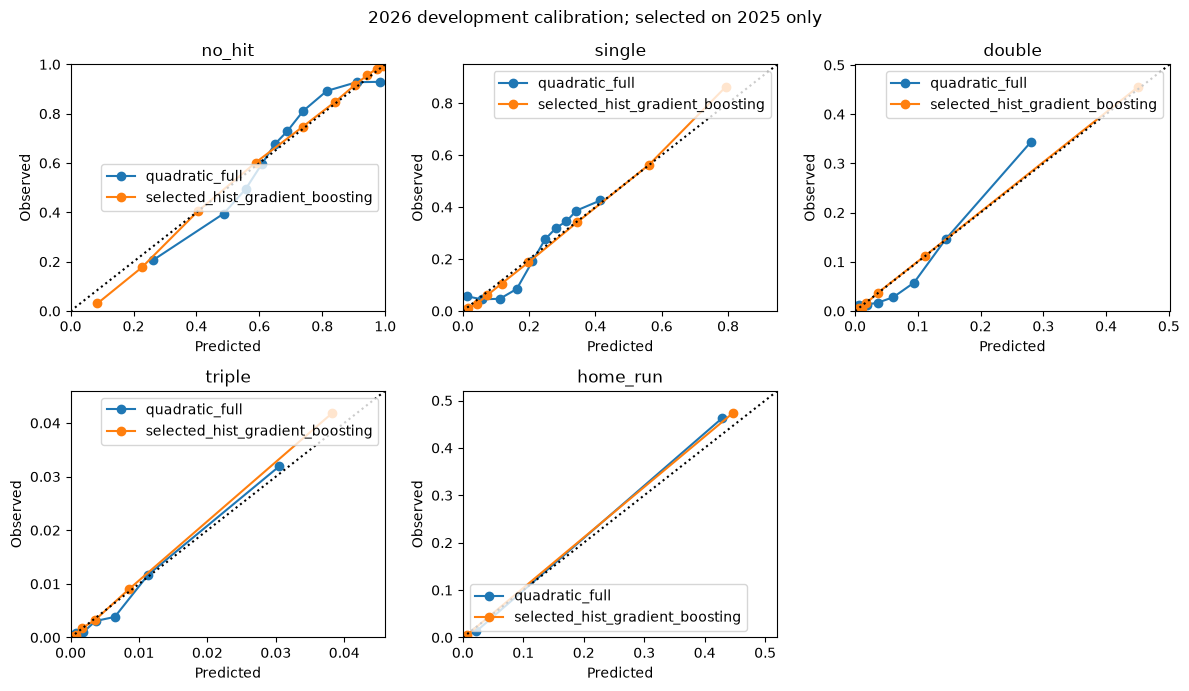

In [56]:
development_calibrations = []
for name, candidate in [("quadratic_full", frozen_models["full"]),
                        (f"selected_{selected_name}", selected_model)]:
    train_prediction = pd.DataFrame(candidate.predict_proba(bat_fit[bat_full_columns]),
                                    index=bat_fit.index, columns=OUTCOMES)
    ece, calibration = calibration_audit(train_prediction, bat_eval, development_probabilities[name])
    calibration["model"] = name
    development_calibrations.append(calibration)
    print(name, "2026 development macro calibration ECE:", ece)
development_calibration = pd.concat(development_calibrations, ignore_index=True)
development_calibration.to_csv(RESULTS_DIR / "xsimpson_v3_model_calibration_2026.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for outcome, ax in zip(OUTCOMES, axes.flat):
    subset = development_calibration.loc[development_calibration["outcome"].eq(outcome)]
    for name, group in subset.groupby("model"):
        ax.plot(group["predicted"], group["actual"], marker="o", label=name)
    limit = min(1, max(0.01, subset[["predicted", "actual"]].max().max()) * 1.1)
    ax.plot([0, limit], [0, limit], "k:")
    ax.set(title=outcome, xlim=(0, limit), ylim=(0, limit), xlabel="Predicted", ylabel="Observed")
    ax.legend()
axes.flat[-1].axis("off")
fig.suptitle("2026 development calibration; selected on 2025 only")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "xsimpson_v3_model_calibration_2026.png", dpi=140)
plt.show()

## Selected-model batting accounting and speed association

Use the selected full model at player and reference speed, with the original
quadratic baseline for missing direction and training frequencies for missing
EV/LA. Keep the same measured-speed reference and missing-speed rule. Unknown
speed uses reference speed in both predictions, giving zero individualized speed
conversion. Negative values are retained. No baserunning is included.

Separate model changes from the verified PA-accounting correction. Compare the
selected and original quadratic model on corrected PA, while retaining the recorded
pre-correction headline. All speed components remain model-based associations.

In [57]:
selected_players = quadratic_players.copy()
selected_contact = bat_eval[["batter", "speed_missing", "prediction_source"]].copy()
selected_contact["expected_contact_credit"] = selected_prob[NON_HR_HITS].dot(bat_run_credits[NON_HR_HITS])
selected_contact["contact_value"] = selected_reference_prob[NON_HR_HITS].dot(bat_run_credits[NON_HR_HITS])
selected_contact["speed_conversion_value"] = (
    selected_contact["expected_contact_credit"] - selected_contact["contact_value"]
)
assert np.allclose(selected_contact.loc[missing_prior_speed, "speed_conversion_value"], 0)
assert np.allclose(selected_contact.loc[prior_fallback_rows, "speed_conversion_value"], 0)
selected_median_frame = bat_eval.copy()
selected_median_frame.loc[missing_prior_speed, "sprint_speed"] = bat_median_speed
selected_median_prob = contact_probabilities(
    selected_model, frozen_models["baseline"], selected_median_frame, bat_prior, bat_type_priors,
)
selected_contact["median_policy_contact_credit"] = selected_median_prob[NON_HR_HITS].dot(bat_run_credits[NON_HR_HITS])
for outcome in HIT_EVENTS:
    selected_contact[f"expected_{outcome}s"] = selected_prob[outcome]
selected_sums = selected_contact.groupby("batter").sum(numeric_only=True)
for column in ["expected_contact_credit", "contact_value", "speed_conversion_value",
               "median_policy_contact_credit", *[f"expected_{outcome}s" for outcome in HIT_EVENTS]]:
    selected_players[column] = selected_sums[column].reindex(selected_players.index, fill_value=0)
selected_players["expected_batting_credit"] = (
    selected_players["walk_HBP_value"] + selected_players["contact_value"]
    + selected_players["speed_conversion_value"]
)
selected_players["xSIMPSON_bat"] = selected_players["expected_batting_credit"] / selected_players["PA"]
selected_players["xSIMPSON_bat_previous_median"] = (
    selected_players["walk_HBP_value"] + selected_players["median_policy_contact_credit"]
) / selected_players["PA"]
selected_players["missing_speed_policy_rate_change"] = (
    selected_players["xSIMPSON_bat"] - selected_players["xSIMPSON_bat_previous_median"]
)

In [58]:
for component, column in [
    ("walk_HBP_value", "walk_HBP_runs_per_600_PA"),
    ("contact_value", "contact_runs_per_600_PA"),
    ("speed_conversion_value", "speed_conversion_runs_per_600_PA"),
]:
    selected_players[column] = 600 * selected_players[component] / selected_players["PA"]
selected_players["batting_credit_per_600_PA"] = 600 * selected_players["xSIMPSON_bat"]
selected_players["official_PA_rate_sensitivity"] = selected_players["expected_batting_credit"] / selected_players["official_PA"]
recorded_players = pd.read_csv(FROZEN_DIR / "xsimpson_v3_batting_results.csv").set_index("batter")
selected_players["quadratic_xSIMPSON_bat_corrected_PA"] = quadratic_players["xSIMPSON_bat"]
selected_players["recorded_quadratic_xSIMPSON_bat"] = recorded_players["xSIMPSON_bat"]
selected_players["PA_accounting_rate_change"] = (
    (recorded_players["walk_HBP_credit"] + recorded_players["expected_contact_credit"])
    / quadratic_players["PA"] - recorded_players["xSIMPSON_bat"]
)
selected_players["model_rate_change"] = (
    selected_players["xSIMPSON_bat"] - quadratic_players["xSIMPSON_bat"]
)
selected_players["selected_model"] = selected_name
assert np.allclose(selected_players["expected_batting_credit"], (
    selected_players["walk_HBP_credit"] + selected_players["expected_contact_credit"]
))
assert np.allclose(selected_players[["walk_HBP_runs_per_600_PA", "contact_runs_per_600_PA",
                                    "speed_conversion_runs_per_600_PA"]].sum(axis=1),
                   600 * selected_players["xSIMPSON_bat"])
assert np.allclose(selected_players.loc[
    selected_players["missing_prior_speed_fraction"].eq(1), "speed_conversion_value"
], 0)
print("Selected-model decomposition identities passed; negative speed values retained:",
      selected_players["speed_conversion_value"].lt(0).sum())
assert np.allclose(
    (quadratic_players["walk_HBP_credit"] + quadratic_players["expected_contact_credit"]).sort_index(),
    (recorded_players["walk_HBP_credit"] + recorded_players["expected_contact_credit"]).sort_index(),
    rtol=1e-10, atol=1e-10,
), "Original quadratic numerical reproduction changed; keep it separate from PA correction."


Selected-model decomposition identities passed; negative speed values retained: 219


In [59]:
impact_rows = []
for name, table in [("recorded_quadratic", recorded_players),
                    ("quadratic_corrected_PA", quadratic_players),
                    (f"selected_{selected_name}", selected_players)]:
    credit = table["walk_HBP_credit"].sum() + table["expected_contact_credit"].sum()
    impact_rows.append({
        "model": name, "scope": "league", "PA": table["PA"].sum(),
        "expected_batting_credit": credit, "xSIMPSON_bat": credit / table["PA"].sum(),
        "contact_runs_per_600_PA": 600 * table["contact_value"].sum() / table["PA"].sum(),
        "speed_runs_per_600_PA": 600 * table["speed_conversion_value"].sum() / table["PA"].sum(),
    })
    simpson = table.loc[SIMPSON_ID]
    impact_rows.append({
        "model": name, "scope": "Simpson", "PA": simpson["PA"],
        "expected_batting_credit": simpson["walk_HBP_credit"] + simpson["expected_contact_credit"],
        "xSIMPSON_bat": simpson["xSIMPSON_bat"],
        "contact_runs_per_600_PA": simpson["contact_runs_per_600_PA"],
        "speed_runs_per_600_PA": simpson["speed_conversion_runs_per_600_PA"],
    })
model_impact = pd.DataFrame(impact_rows)
model_impact.to_csv(RESULTS_DIR / "xsimpson_v3_model_impact.csv", index=False)
display(model_impact.round(6))
selected_players = selected_players.sort_values("xSIMPSON_bat", ascending=False)
selected_players.to_csv(RESULTS_DIR / "xsimpson_v3_batting_results.csv")
selected_display = ["Name", "PA", "xSIMPSON_bat", "observed_SIMPSON_bat",
                    "walk_HBP_runs_per_600_PA", "contact_runs_per_600_PA",
                    "speed_conversion_runs_per_600_PA", "model_rate_change",
                    "missing_prior_speed_fraction", "selected_model"]
qualified = selected_players.loc[selected_players["PA"].ge(BATTING_DISPLAY_MIN_PA), selected_display]
qualified.to_csv(RESULTS_DIR / "xsimpson_v3_batting_leaderboard.csv")
display(qualified.head(20).round(5))
display(selected_players.loc[selected_players.index == SIMPSON_ID, selected_display].round(5))

,model,scope,PA,expected_batting_credit,xSIMPSON_bat,contact_runs_per_600_PA,speed_runs_per_600_PA
0,recorded_quadratic,league,183849,37410.675680,0.203486,88.474163,0.474845
1,recorded_quadratic,Simpson,612,136.157396,0.222479,110.209989,9.452517
2,quadratic_corrected_PA,league,183849,37410.675680,0.203486,88.474163,0.474845
3,quadratic_corrected_PA,Simpson,612,136.157396,0.222479,110.209989,9.452517
4,selected_hist_gradient_boosting,league,183849,37334.318649,0.203071,88.851629,-0.151816
5,selected_hist_gradient_boosting,Simpson,612,129.309696,0.211290,107.162141,5.786933


,Name,PA,xSIMPSON_bat,observed_SIMPSON_bat,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,model_rate_change,missing_prior_speed_fraction,selected_model
batter,,,,,,,,,,
680757,Steven Kwan,637,0.25420,0.25885,46.84877,106.28609,-0.61335,0.00269,0.0,hist_gradient_boosting
803011,Sam Antonacci,557,0.25396,0.25314,44.52897,107.84641,0.00000,0.00196,1.0,hist_gradient_boosting
672695,Geraldo Perdomo,680,0.25064,0.24626,50.37850,100.92603,-0.92040,0.00249,0.0,hist_gradient_boosting
672515,Gabriel Moreno,549,0.24548,0.25869,40.82331,107.99636,-1.53437,0.00908,0.0,hist_gradient_boosting
681198,TJ Rumfield,631,0.24498,0.25933,44.21875,102.76960,0.00000,0.01015,1.0,hist_gradient_boosting
663538,Nico Hoerner,689,0.24138,0.22106,26.25151,116.54910,2.03018,0.00692,0.0,hist_gradient_boosting
693304,Nick Gonzales,608,0.23942,0.25716,31.49277,109.95908,2.20066,0.00400,0.0,hist_gradient_boosting
621493,Taylor Ward,607,0.23897,0.23214,58.15930,85.85817,-0.63748,0.00544,0.0,hist_gradient_boosting
800050,Chase DeLauter,559,0.23860,0.24183,36.35306,106.80633,0.00000,-0.00008,1.0,hist_gradient_boosting


,Name,PA,xSIMPSON_bat,observed_SIMPSON_bat,walk_HBP_runs_per_600_PA,contact_runs_per_600_PA,speed_conversion_runs_per_600_PA,model_rate_change,missing_prior_speed_fraction,selected_model
batter,,,,,,,,,,
802415,Chandler Simpson,612,0.21129,0.24209,13.82514,107.16214,5.78693,-0.01119,0.0,hist_gradient_boosting


The recorded quadratic model remains available with its original settings, fitted
pipelines, contact predictions, player tables, and notebook snapshot. The selected
approach is determined only by the predeclared 2025 validation rule. 2026 tables
are development diagnostics and cannot establish untouched future performance.

Multiclass metrics and outcome-frequency diagnostics apply to models with full
probability vectors; Statcast comparisons use only its scalar xwOBA and matching
raw event accounting. Signed errors are predicted minus observed. Missing-contact
and observed-accounting exclusions remain explicit, and model changes are separated
from the verified PA-attribution correction. Speed conversion is associative;
baserunning remains a separate next component.

Recorded diagnostic finding: the original line-drive error is dominated by
underpredicted singles, especially lower-angle and lower-EV training-derived
ranges. Very few line drives lack contact measurements or fail shared-accounting
eligibility, so those exclusions cannot explain most of the gap. The flexible
model's improvement on 2025 validation supports a functional-form limitation in
the quadratic surface. It remains an empirical model comparison, not a causal
explanation. Residual contact-type bias, rare outcomes, imputation-policy effects,
and future-season generalization remain limitations; no PA discrepancy remains
unresolved in the checked 2026 season-total source.


## Feature-leakage and information audit

Preserve the selected HGB model and every previously saved result as the recorded
benchmark. This section does not alter selection or batting accounting. It asks
where the HGB improvement comes from using a fixed 2024 training / 2025 validation
ablation; 2025 is now reused development validation, and 2026 remains development
data. Simpson is excluded from both fitting and this model comparison.

Every estimator receives an explicit numeric allowlist. `events` supplies the
training label and contact-accounting convention; `des` only excludes identified
foul outs before modeling. `woba_value`, Statcast xwOBA, and all expected-stat
fields stay in a separate eligibility/evaluation table and never enter an
estimator feature matrix. PA results and
post-play descriptions never enter an estimator. `bb_type` is not a fitted-model
input, but it selects a training-only empirical prior when EV/LA or handedness is
missing; that small fallback effect is tested separately below.

### Spray-coordinate scope and physical interpretation

The [official Statcast CSV documentation](https://baseballsavant.mlb.com/csv-docs)
defines `hc_x` and `hc_y` only as the batted ball's X and Y *hit coordinates*. It
does not document whether the point is a landing point, fielding point, stopped-ball
point, or radar-derived physical coordinate. The constants `(125.42, 198.27)` are
the approximate chart origin already used by this prototype; their provenance is
not recorded by MLB or by the original notebook, so that origin is an assumption.

The formula is `atan2(hc_x - 125.42, 198.27 - hc_y)`: zero points toward the top of
the chart, positive values toward the right-field side in batter-view descriptions,
and negative values toward the left-field side. It assumes equal chart-axis scale.
Raw coordinates and radial distance do **not** enter an estimator. Descriptions
and near-home points suggest the chart may represent a general play/fielding
location for at least some bunts and catcher plays, but that is an empirical clue,
not documented proof of a consistent physical endpoint. Direction is therefore
an intentional post-contact chart feature with measurement-semantic uncertainty.

In [60]:
SPRAY_ORIGIN = (125.42, 198.27)
spray_check = bat_contact[
    ["season", "outcome", "events", "bb_group", "hc_x", "hc_y", "spray_angle", "des"]
].copy()
spray_check["coordinate_missing"] = spray_check[["hc_x", "hc_y"]].isna().any(axis=1)
spray_check["chart_radius"] = np.hypot(
    spray_check["hc_x"] - SPRAY_ORIGIN[0], SPRAY_ORIGIN[1] - spray_check["hc_y"]
)
spray_check["nominal_outside_45_degrees"] = spray_check["spray_angle"].abs().gt(45)
spray_check["behind_origin_abs_angle_gt_90"] = spray_check["spray_angle"].abs().gt(90)
spray_check["near_origin_radius_lt_10"] = spray_check["chart_radius"].lt(10)
spray_angle_audit = spray_check.groupby(["season", "outcome"], sort=False).agg(
    fair_contact_rows=("events", "size"), missing_coordinates=("coordinate_missing", "sum"),
    missing_coordinate_fraction=("coordinate_missing", "mean"),
    nominal_outside_45=("nominal_outside_45_degrees", "sum"),
    behind_origin=("behind_origin_abs_angle_gt_90", "sum"),
    near_origin=("near_origin_radius_lt_10", "sum"),
    minimum_angle=("spray_angle", "min"), maximum_angle=("spray_angle", "max"),
).reset_index()
spray_angle_audit.to_csv(
    RESULTS_DIR / "xsimpson_v3_spray_angle_audit.csv", index=False,
)
display(spray_angle_audit.round(6))
print("Angles outside +/-45 are nominal chart flags, not automatic invalid plays.")

,season,outcome,fair_contact_rows,missing_coordinates,missing_coordinate_fraction,nominal_outside_45,behind_origin,near_origin,minimum_angle,maximum_angle
0,2024,no_hit,80839,6,0.000074,4756,375,1331,-179.634482,179.823706
1,2024,single,25902,4,0.000154,1027,64,296,-176.693254,179.530373
2,2024,double,7771,2,0.000257,1824,4,5,-89.390253,174.681213
3,2024,home_run,5453,35,0.006418,259,0,0,-49.738304,50.158121
4,2024,triple,697,1,0.001435,155,1,1,-50.073233,174.681213
5,2025,home_run,5650,32,0.005664,266,1,0,-49.434957,104.170530
6,2025,no_hit,81269,10,0.000123,5095,420,1436,-179.809015,180.000000
7,2025,single,26115,1,0.000038,1027,64,313,-166.870834,178.801518
8,2025,double,7745,3,0.000387,1800,6,5,-153.527436,174.681213
9,2025,triple,628,0,0.000000,134,0,0,-49.444581,50.309729


Angles outside +/-45 are nominal chart flags, not automatic invalid plays.


In [61]:
direction_text = spray_check["des"].str.extract(
    r"\bto (?:deep |shallow )?(left|center|right)(?: field| fielder)?\b",
    flags=0, expand=False,
)
spray_check["description_direction"] = direction_text
spray_check["description_sign_agrees"] = np.select(
    [direction_text.eq("left"), direction_text.eq("right"), direction_text.eq("center")],
    [spray_check["spray_angle"].lt(0), spray_check["spray_angle"].gt(0),
     spray_check["spray_angle"].abs().le(15)],
    default=np.nan,
)
spray_description_audit = spray_check.loc[direction_text.notna()].groupby(
    ["season", "outcome", "description_direction"], sort=False
).agg(
    rows=("events", "size"), median_spray_angle=("spray_angle", "median"),
    sign_or_center_agreement=("description_sign_agrees", "mean"),
).reset_index()
spray_description_audit.to_csv(
    RESULTS_DIR / "xsimpson_v3_spray_description_audit.csv", index=False,
)
display(spray_description_audit.round(4))

,season,outcome,description_direction,rows,median_spray_angle,sign_or_center_agreement
0,2024,single,right,7524,30.5794,0.9995
1,2024,no_hit,center,12474,0.4844,0.9227
2,2024,no_hit,right,9535,29.6221,0.9995
3,2024,no_hit,left,8932,-28.3521,0.9981
4,2024,single,center,7373,0.6837,0.9414
5,2024,double,right,2419,42.0474,0.9988
6,2024,single,left,6954,-27.5669,0.9981
7,2024,double,center,1808,-4.2675,0.6504
8,2024,home_run,left,2290,-31.0314,0.9934
9,2024,double,left,3277,-42.0467,0.9976


### Fixed HGB feature ablation

All three boosted models use the existing fixed HGB settings, the same 2024
complete-coordinate fitting rows, and the same 2025 eligible comparison plays.
Training missing speed is replaced with the 2024 training median; validation
missing speed uses the 2024 unique-batter-season reference. No validation outcome
sets preprocessing, priors, coordinates, or bin boundaries.

- A: exit velocity, launch angle, and handedness.
- B: A plus prior-season Sprint Speed and its missingness indicator.
- C: B plus chart-derived spray angle (the already selected HGB specification).

The recorded quadratic C model remains the flexibility reference. Statcast supplies
only scalar xwOBA, so its log loss, class Brier scores, and calibration are
unavailable rather than inferred.

In [62]:
audit_source = load_csv(DATA_DIR / "statcast_expected_woba_2025.csv", [
    *pitch_keys, "batter", "events", "game_type",
    "estimated_woba_using_speedangle", "woba_value", "woba_denom",
])
assert not audit_source.duplicated(pitch_keys).any()
audit_hit_weights = audit_source.loc[
    audit_source["game_type"].eq("R") & audit_source["events"].isin(HIT_EVENTS)
].groupby("events")["woba_value"].agg(["min", "max", "nunique"])
assert set(audit_hit_weights.index) == set(HIT_EVENTS)
assert audit_hit_weights["nunique"].eq(1).all()
audit_weights = audit_hit_weights["min"].reindex(OUTCOMES).fillna(0)
audit_benchmark = validation_complete[
    [*pitch_keys, "batter", "outcome", "bb_group"]
].reset_index(names="model_index").merge(
    audit_source.drop(columns=["events", "game_type"]),
    on=[*pitch_keys, "batter"], how="left", validate="one_to_one",
).set_index("model_index")
audit_benchmark["observed_class_weight"] = audit_benchmark["outcome"].map(audit_weights)
audit_benchmark["shared"] = (
    np.isfinite(audit_benchmark["estimated_woba_using_speedangle"])
    & audit_benchmark["woba_denom"].eq(1)
    & np.isclose(audit_benchmark["woba_value"], audit_benchmark["observed_class_weight"])
)
audit_eval = validation_complete.loc[audit_benchmark["shared"]]
assert np.allclose(audit_benchmark.loc[audit_eval.index, "woba_value"],
                   audit_eval["outcome"].map(audit_weights))
print("2025 complete rows:", len(validation_complete),
      "identical model/Statcast rows:", len(audit_eval))

2025 complete rows: 120544 identical model/Statcast rows: 118613


In [63]:
ABLATION_FEATURES = {
    "HGB_A_contact": ["launch_speed", "launch_angle", "left_handed"],
    "HGB_B_speed": bat_baseline_columns,
    "HGB_C_direction": bat_full_columns,
}
ablation_models = {}
for name, columns in ABLATION_FEATURES.items():
    if name == "HGB_C_direction":
        fitted = selection_hgb
    else:
        fitted = HistGradientBoostingClassifier(**HGB_SETTINGS)
        with threadpool_limits(limits=4):
            fitted.fit(selection_fit[columns], selection_fit["outcome_code"])
    assert list(fitted.feature_names_in_) == columns
    assert np.array_equal(fitted.classes_, np.arange(len(OUTCOMES)))
    ablation_models[name] = fitted

audit_models = {"quadratic_C": selection_quadratic["full"], **ablation_models}
audit_features = {"quadratic_C": bat_full_columns, **ABLATION_FEATURES}
audit_probabilities = {}
audit_training_probabilities = {}
for name, fitted in audit_models.items():
    columns = audit_features[name]
    audit_probabilities[name] = pd.DataFrame(
        fitted.predict_proba(audit_eval[columns]), index=audit_eval.index, columns=OUTCOMES,
    )
    audit_training_probabilities[name] = pd.DataFrame(
        fitted.predict_proba(selection_fit[columns]), index=selection_fit.index, columns=OUTCOMES,
    )
    assert np.allclose(audit_probabilities[name].sum(axis=1), 1)
assert np.allclose(audit_probabilities["HGB_C_direction"],
                   selection_predictions["hist_gradient_boosting"].loc[audit_eval.index])
print("HGB C is the preserved selected model; no specification or prediction changed.")

HGB C is the preserved selected model; no specification or prediction changed.


In [64]:
feature_sources = {
    "launch_speed": ("launch_speed", "raw Statcast exit velocity"),
    "launch_angle": ("launch_angle", "raw Statcast launch angle"),
    "sprint_speed": ("player_id + prior season", "prior-season join; training-only replacement"),
    "left_handed": ("stand", "1 for L, 0 for R"),
    "speed_missing": ("sprint_speed", "1 when prior-season speed is missing"),
    "spray_angle": ("hc_x + hc_y", "atan2 chart direction around (125.42, 198.27)"),
}
model_specs = {
    "ground_binary_quadratic_baseline": baseline_columns,
    "ground_binary_quadratic_full": full_columns,
    "all_contact_quadratic_baseline": bat_baseline_columns,
    "all_contact_quadratic_full": bat_full_columns,
    "2024_selection_quadratic_baseline": bat_baseline_columns,
    "2024_selection_quadratic_full": bat_full_columns,
    "2024_selection_HGB_C": bat_full_columns,
    "2024_2025_selected_HGB_C": bat_full_columns,
    **{f"ablation_{name}": columns for name, columns in ABLATION_FEATURES.items()},
}
forbidden = {"events", "outcome", "outcome_code", "woba_value",
             "estimated_woba_using_speedangle", "des", "description", "bb_type"}
assert all(not forbidden.intersection(columns) for columns in model_specs.values())
feature_rows = []
for model_name, columns in model_specs.items():
    for feature in columns:
        source, construction = feature_sources[feature]
        feature_rows.append({"model": model_name, "input_feature": feature,
                             "source_columns": source, "construction": construction})
feature_audit = pd.DataFrame(feature_rows)
feature_audit.to_csv(RESULTS_DIR / "xsimpson_v3_model_feature_audit.csv", index=False)
display(feature_audit)

,model,input_feature,source_columns,construction
0,ground_binary_quadratic_baseline,launch_speed,launch_speed,raw Statcast exit velocity
1,ground_binary_quadratic_baseline,launch_angle,launch_angle,raw Statcast launch angle
2,ground_binary_quadratic_baseline,sprint_speed,player_id + prior season,prior-season join; training-only replacement
3,ground_binary_quadratic_baseline,left_handed,stand,"1 for L, 0 for R"
4,ground_binary_quadratic_baseline,speed_missing,sprint_speed,1 when prior-season speed is missing
5,ground_binary_quadratic_full,launch_speed,launch_speed,raw Statcast exit velocity
6,ground_binary_quadratic_full,launch_angle,launch_angle,raw Statcast launch angle
7,ground_binary_quadratic_full,sprint_speed,player_id + prior season,prior-season join; training-only replacement
8,ground_binary_quadratic_full,left_handed,stand,"1 for L, 0 for R"
9,ground_binary_quadratic_full,speed_missing,sprint_speed,1 when prior-season speed is missing


In [65]:
fitted_feature_checks = {
    "all_contact_quadratic_baseline": (frozen_models["baseline"], bat_baseline_columns),
    "all_contact_quadratic_full": (frozen_models["full"], bat_full_columns),
    "2024_selection_quadratic_baseline": (selection_quadratic["baseline"], bat_baseline_columns),
    "2024_selection_quadratic_full": (selection_quadratic["full"], bat_full_columns),
    "2024_selection_HGB_C": (selection_hgb, bat_full_columns),
    "2024_2025_selected_model": (selected_model, bat_full_columns),
}
for name, fitted in ablation_models.items():
    fitted_feature_checks[f"ablation_{name}"] = (fitted, ABLATION_FEATURES[name])
for model_name, (fitted, expected) in fitted_feature_checks.items():
    assert list(fitted.feature_names_in_) == expected, model_name

polynomial_rows = []
for model_name, columns in model_specs.items():
    if "quadratic" not in model_name:
        continue
    terms = PolynomialFeatures(degree=2, include_bias=False).fit(
        selection_fit[columns]
    ).get_feature_names_out(columns)
    polynomial_rows.extend({"model": model_name, "derived_term": term,
                            "inputs_standardized_before_expansion": True} for term in terms)
polynomial_audit = pd.DataFrame(polynomial_rows)
polynomial_audit.to_csv(
    RESULTS_DIR / "xsimpson_v3_quadratic_derived_features.csv", index=False,
)
excluded_audit = pd.DataFrame([
    (field, role, False) for field, role in [
        ("events/outcome", "label and fair-contact accounting"),
        ("des/description", "foul-out row exclusion and manual review"),
        ("bb_type", "diagnostic strata and missing-contact prior only"),
        ("woba_value", "evaluation target joined after prediction"),
        ("estimated_woba_using_speedangle", "scalar benchmark joined after prediction"),
        ("hc_x/hc_y/radius", "raw coordinates and radius excluded; angle only"),
    ]
], columns=["field", "non_predictor_role", "enters_fitted_estimator"])
excluded_audit.to_csv(RESULTS_DIR / "xsimpson_v3_excluded_feature_audit.csv", index=False)
print("All retained fitted estimators passed exact feature-name allowlist checks.")

All retained fitted estimators passed exact feature-name allowlist checks.


In [66]:
fallback_feature_audit = pd.DataFrame([
    {
        "route": "missing direction", "rows_eligible_when": "EV/LA and handedness available",
        "evaluation_inputs": ", ".join(bat_baseline_columns),
        "training_information": "quadratic baseline fitted on training rows only",
    },
    {
        "route": "missing EV/LA or handedness", "rows_eligible_when": "baseline unavailable",
        "evaluation_inputs": "bb_type (post-contact source classification)",
        "training_information": "training outcome frequencies within bb_type",
    },
    {
        "route": "unknown bb_type", "rows_eligible_when": "baseline and type unavailable",
        "evaluation_inputs": "none", "training_information": "global training outcome frequencies",
    },
    {
        "route": "missing prior speed", "rows_eligible_when": "speed_missing == 1",
        "evaluation_inputs": "speed_missing plus training replacement speed",
        "training_information": "training median/reference; no validation outcome",
    },
])
fallback_feature_audit.to_csv(
    RESULTS_DIR / "xsimpson_v3_fallback_feature_audit.csv", index=False,
)
display(fallback_feature_audit)

,route,rows_eligible_when,evaluation_inputs,training_information
0,missing direction,EV/LA and handedness available,"launch_speed, launch_angle, sprint_speed, left...",quadratic baseline fitted on training rows only
1,missing EV/LA or handedness,baseline unavailable,bb_type (post-contact source classification),training outcome frequencies within bb_type
2,unknown bb_type,baseline and type unavailable,none,global training outcome frequencies
3,missing prior speed,speed_missing == 1,speed_missing plus training replacement speed,training median/reference; no validation outcome


In [67]:
def calibration_by_class(training_probabilities, frame, probabilities):
    details = []
    class_ece = {}
    for outcome in OUTCOMES:
        edges = np.unique(np.r_[
            -np.inf, training_probabilities[outcome].quantile(np.arange(.1, 1, .1)), np.inf,
        ])
        bins = pd.cut(probabilities[outcome], edges)
        values = pd.DataFrame({
            "bin": bins, "predicted": probabilities[outcome],
            "actual": frame["outcome"].eq(outcome).astype(int),
        }).groupby("bin", observed=True).agg(
            rows=("actual", "size"), mean_prediction=("predicted", "mean"),
            observed_frequency=("actual", "mean"),
        ).reset_index(drop=True)
        values["outcome"] = outcome
        values["absolute_gap"] = (
            values["mean_prediction"] - values["observed_frequency"]
        ).abs()
        class_ece[outcome] = (values["rows"] * values["absolute_gap"]).sum() / len(frame)
        details.append(values)
    return class_ece, pd.concat(details, ignore_index=True)

audit_metric_rows = []
audit_calibration_rows = []

In [68]:
for bb_type, frame in [("overall", audit_eval)] + list(audit_eval.groupby("bb_group")):
    for name, probabilities in audit_probabilities.items():
        prediction = probabilities.loc[frame.index]
        row = outcome_metrics(frame, prediction, audit_weights)
        class_ece, detail = calibration_by_class(
            audit_training_probabilities[name], frame, prediction,
        )
        for outcome, value in class_ece.items():
            row[f"calibration_ECE_{outcome}"] = value
        row["calibration_ECE_macro"] = np.mean(list(class_ece.values()))
        row.update(model=name, bb_type=bb_type, evaluation="2025_reused_development")
        audit_metric_rows.append(row)
        detail["model"] = name
        detail["bb_type"] = bb_type
        audit_calibration_rows.append(detail)
    observed = audit_benchmark.loc[frame.index, "woba_value"]
    statcast = audit_benchmark.loc[frame.index, "estimated_woba_using_speedangle"]
    error = statcast - observed
    row = {"model": "Statcast_xwOBA", "bb_type": bb_type, "rows": len(frame),
           "evaluation": "2025_reused_development", "log_loss": np.nan,
           "event_value_RMSE": np.sqrt(np.mean(error ** 2)),
           "wOBA_error_predicted_minus_observed": error.mean()}
    for outcome in OUTCOMES:
        row[f"actual_{outcome}"] = frame["outcome"].eq(outcome).mean()
        row[f"predicted_{outcome}"] = np.nan
        row[f"Brier_{outcome}"] = np.nan
        row[f"calibration_ECE_{outcome}"] = np.nan
    row["calibration_ECE_macro"] = np.nan
    audit_metric_rows.append(row)

feature_ablation_metrics = pd.DataFrame(audit_metric_rows)
feature_ablation_calibration = pd.concat(audit_calibration_rows, ignore_index=True)
feature_ablation_metrics.to_csv(
    RESULTS_DIR / "xsimpson_v3_feature_ablation_metrics_2025.csv", index=False,
)
feature_ablation_calibration.to_csv(
    RESULTS_DIR / "xsimpson_v3_feature_ablation_calibration_2025.csv", index=False,
)

In [69]:
effect_pairs = [
    ("model_flexibility", "quadratic_C", "HGB_C_direction"),
    ("prior_speed", "HGB_A_contact", "HGB_B_speed"),
    ("chart_direction", "HGB_B_speed", "HGB_C_direction"),
]
loss_metrics = ["log_loss", "event_value_RMSE", "calibration_ECE_macro"] + [
    f"Brier_{outcome}" for outcome in OUTCOMES
]
effect_rows = []
for bb_type in feature_ablation_metrics["bb_type"].unique():
    values = feature_ablation_metrics.loc[
        feature_ablation_metrics["bb_type"].eq(bb_type)
    ].set_index("model")
    for component, reference, new in effect_pairs:
        for metric in loss_metrics + ["wOBA_error_predicted_minus_observed"]:
            old_value, new_value = values.loc[reference, metric], values.loc[new, metric]
            effect_rows.append({
                "bb_type": bb_type, "component": component, "metric": metric,
                "reference_model": reference, "new_model": new,
                "reference_value": old_value, "new_value": new_value,
                "new_minus_reference": new_value - old_value,
                "loss_reduction_reference_minus_new": (
                    old_value - new_value if metric in loss_metrics else np.nan
                ),
            })
feature_ablation_effects = pd.DataFrame(effect_rows)
feature_ablation_effects.to_csv(
    RESULTS_DIR / "xsimpson_v3_feature_ablation_effects_2025.csv", index=False,
)
display(feature_ablation_metrics.loc[
    feature_ablation_metrics["bb_type"].eq("overall"),
    ["model", "rows", "log_loss", "event_value_RMSE",
     "wOBA_error_predicted_minus_observed", "calibration_ECE_macro",
     *[f"Brier_{outcome}" for outcome in OUTCOMES]],
].round(6))
display(feature_ablation_effects.loc[
    feature_ablation_effects["bb_type"].eq("overall")
    & feature_ablation_effects["metric"].isin(
        ["log_loss", "event_value_RMSE", "calibration_ECE_macro"]
    )
].round(6))

,model,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed,calibration_ECE_macro,Brier_no_hit,Brier_single,Brier_double,Brier_triple,Brier_home_run
0,quadratic_C,118613,0.701921,0.451325,0.005605,0.020076,0.171972,0.152007,0.050071,0.005147,0.016517
1,HGB_A_contact,118613,0.580334,0.435819,0.007751,0.004369,0.137238,0.110997,0.052680,0.005183,0.020134
2,HGB_B_speed,118613,0.580823,0.436249,0.007693,0.004958,0.137430,0.111011,0.052790,0.005164,0.020216
3,HGB_C_direction,118613,0.466968,0.377257,0.006166,0.007232,0.112515,0.093982,0.038307,0.005060,0.014025
4,Statcast_xwOBA,118613,NaN,0.434942,-0.000646,NaN,NaN,NaN,NaN,NaN,NaN


,bb_type,component,metric,reference_model,new_model,reference_value,new_value,new_minus_reference,loss_reduction_reference_minus_new
0,overall,model_flexibility,log_loss,quadratic_C,HGB_C_direction,0.701921,0.466968,-0.234954,0.234954
1,overall,model_flexibility,event_value_RMSE,quadratic_C,HGB_C_direction,0.451325,0.377257,-0.074068,0.074068
2,overall,model_flexibility,calibration_ECE_macro,quadratic_C,HGB_C_direction,0.020076,0.007232,-0.012844,0.012844
9,overall,prior_speed,log_loss,HGB_A_contact,HGB_B_speed,0.580334,0.580823,0.000489,-0.000489
10,overall,prior_speed,event_value_RMSE,HGB_A_contact,HGB_B_speed,0.435819,0.436249,0.000430,-0.000430
11,overall,prior_speed,calibration_ECE_macro,HGB_A_contact,HGB_B_speed,0.004369,0.004958,0.000590,-0.000590
18,overall,chart_direction,log_loss,HGB_B_speed,HGB_C_direction,0.580823,0.466968,-0.113855,0.113855
19,overall,chart_direction,event_value_RMSE,HGB_B_speed,HGB_C_direction,0.436249,0.377257,-0.058992,0.058992
20,overall,chart_direction,calibration_ECE_macro,HGB_B_speed,HGB_C_direction,0.004958,0.007232,0.002274,-0.002274


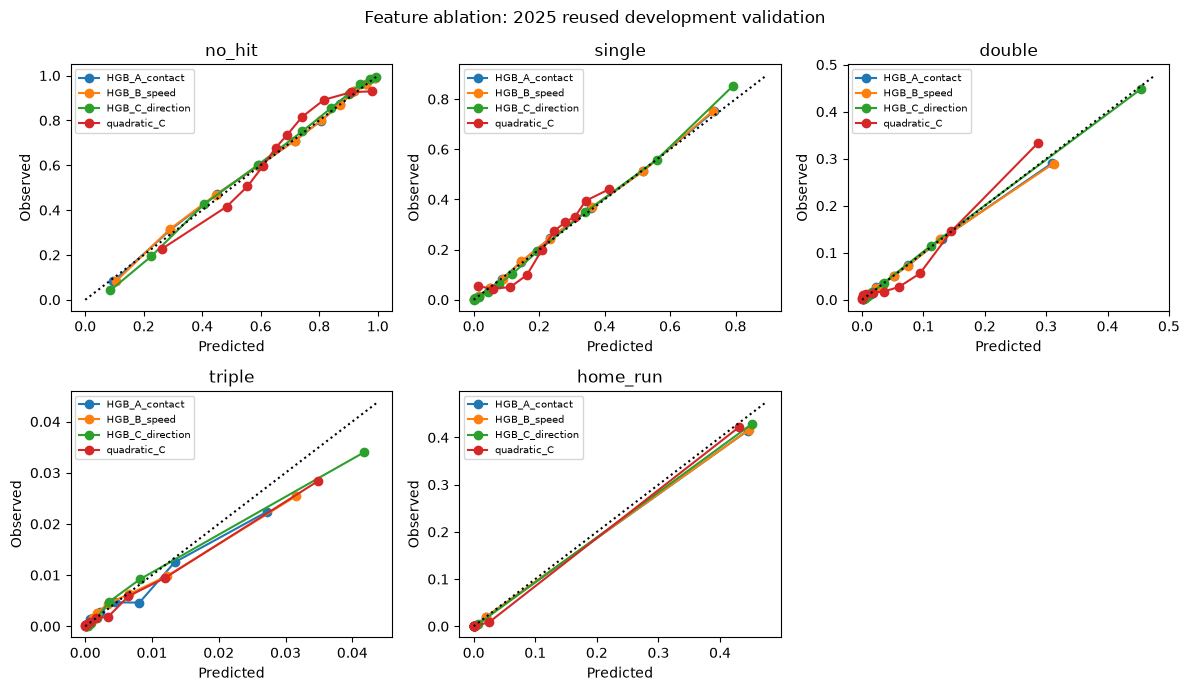

In [70]:
overall_calibration = feature_ablation_calibration.loc[
    feature_ablation_calibration["bb_type"].eq("overall")
]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for outcome, ax in zip(OUTCOMES, axes.flat):
    for name, group in overall_calibration.loc[
        overall_calibration["outcome"].eq(outcome)
    ].groupby("model"):
        ax.plot(group["mean_prediction"], group["observed_frequency"],
                marker="o", label=name)
    limit = min(1, max(.01, ax.get_xlim()[1], ax.get_ylim()[1]))
    ax.plot([0, limit], [0, limit], "k:")
    ax.set(title=outcome, xlabel="Predicted", ylabel="Observed")
    ax.legend(fontsize=7)
axes.flat[-1].axis("off")
fig.suptitle("Feature ablation: 2025 reused development validation")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "xsimpson_v3_feature_ablation_calibration_2025.png", dpi=140)
plt.show()

### `bb_type` is a fallback input, not a fitted-model feature

`bb_type` is the source's post-contact trajectory class. It does not appear in any
estimator `feature_names_in_`. For the current all-contact scoring policy only,
rows lacking EV/LA or handedness receive the 2024 outcome distribution for their
`bb_type`; the comparison below replaces that with the 2024 global distribution.
This isolates the post-contact classification from HGB A/B/C and from selection on
complete rows.

In [71]:
empty_type_priors = selection_type_priors.iloc[0:0]
type_prior_prob = contact_probabilities(
    selection_hgb, selection_quadratic["baseline"], selection_eval,
    selection_prior, selection_type_priors,
)
global_prior_prob = contact_probabilities(
    selection_hgb, selection_quadratic["baseline"], selection_eval,
    selection_prior, empty_type_priors,
)
type_fallback_rows = ~selection_eval["baseline_available"]
assert np.allclose(type_prior_prob.loc[~type_fallback_rows],
                   global_prior_prob.loc[~type_fallback_rows])
fallback_rows = []
for scope, frame in [("all_contact", selection_eval),
                     ("missing_contact_inputs_only", selection_eval.loc[type_fallback_rows])]:
    for name, probabilities in [("bb_type_training_prior", type_prior_prob),
                                ("global_training_prior", global_prior_prob)]:
        row = outcome_metrics(
            frame, probabilities.loc[frame.index], validation_event_weights,
        )
        row.update(scope=scope, fallback=name,
                   bb_type_enters_fitted_estimator=False)
        fallback_rows.append(row)
bb_type_fallback_effect = pd.DataFrame(fallback_rows)
bb_type_fallback_effect.to_csv(
    RESULTS_DIR / "xsimpson_v3_bb_type_fallback_effect_2025.csv", index=False,
)
print("Rows whose prediction uses a bb_type prior:", type_fallback_rows.sum())
display(bb_type_fallback_effect[[
    "scope", "fallback", "rows", "log_loss", "event_value_RMSE",
    "wOBA_error_predicted_minus_observed",
]].round(6))

Rows whose prediction uses a bb_type prior: 446


,scope,fallback,rows,log_loss,event_value_RMSE,wOBA_error_predicted_minus_observed
0,all_contact,bb_type_training_prior,121034,0.464127,0.374627,0.009780
1,all_contact,global_training_prior,121034,0.464509,0.374862,0.010245
2,missing_contact_inputs_only,bb_type_training_prior,446,0.501655,0.359101,0.097463
3,missing_contact_inputs_only,global_training_prior,446,0.605204,0.420351,0.223865


### Representative direction-driven changes

Rank the largest absolute C-minus-B changes in predicted HR-inclusive event value,
separately for actual singles and outs. The review table includes the full play
description, raw chart point, diagnostic radius, exact-pair frequency, and nominal
geometry flags. Agreement with words such as “to left/right/center” checks chart
orientation only; it cannot establish that the coordinate was recorded independently
of the result or that direction is a repeatable batter skill.

In [72]:
review = audit_eval[
    ["game_date", *pitch_keys, "batter", "stand", "events", "outcome", "bb_group",
     "launch_speed", "launch_angle", "hc_x", "hc_y", "spray_angle", "des"]
].copy()
for name in ["HGB_B_speed", "HGB_C_direction"]:
    review[f"{name}_single_probability"] = audit_probabilities[name]["single"]
    review[f"{name}_event_value"] = audit_probabilities[name].dot(audit_weights)
review["direction_event_value_change"] = review[
    "HGB_C_direction_event_value"
] - review["HGB_B_speed_event_value"]
review["chart_radius"] = np.hypot(review["hc_x"] - SPRAY_ORIGIN[0],
                                  SPRAY_ORIGIN[1] - review["hc_y"])
coordinate_counts = selection_eval.groupby(["hc_x", "hc_y"]).size()
review["exact_coordinate_pair_count"] = pd.MultiIndex.from_frame(
    review[["hc_x", "hc_y"]]
).map(coordinate_counts)
review["nominal_outside_45"] = review["spray_angle"].abs().gt(45)
review["behind_origin"] = review["spray_angle"].abs().gt(90)
review["near_origin"] = review["chart_radius"].lt(10)
review["description_direction"] = review["des"].str.extract(
    r"\bto (?:deep |shallow )?(left|center|right)(?: field| fielder)?\b", expand=False)
out_events = FAIR_EVENTS - set(HIT_EVENTS) - {"field_error", "fielders_choice"}
review_groups = [("single", review["outcome"].eq("single")), ("out", review["events"].isin(out_events))]
reviewed_plays = []
for label, mask in review_groups:
    chosen = review.loc[mask].assign(
        absolute_direction_change=review.loc[mask, "direction_event_value_change"].abs()
    ).nlargest(10, "absolute_direction_change")
    chosen["review_group"] = label
    reviewed_plays.append(chosen)
reviewed_plays = pd.concat(reviewed_plays).sort_values(
    ["review_group", "absolute_direction_change"], ascending=[True, False])
reviewed_plays.to_csv(RESULTS_DIR / "xsimpson_v3_direction_change_plays_2025.csv",
                      index=False)
review_display = [
    "review_group", "game_date", "game_pk", "batter", "events", "bb_group",
    "launch_speed", "launch_angle", "spray_angle", "chart_radius",
    "direction_event_value_change", "exact_coordinate_pair_count",
    "nominal_outside_45", "behind_origin", "near_origin", "des",
]
display(reviewed_plays[review_display])

,review_group,game_date,game_pk,batter,events,bb_group,launch_speed,launch_angle,spray_angle,chart_radius,direction_event_value_change,exact_coordinate_pair_count,nominal_outside_45,behind_origin,near_origin,des
292251,out,2025-07-05,777225,593871,field_out,fly_ball,100.5,43.0,46.467528,130.595961,1.566848,1,True,False,False,Jorge Polanco flies out sharply to right field...
187335,out,2025-04-08,778406,542303,field_out,fly_ball,102.8,43.0,-44.837334,141.966401,1.483800,1,False,False,False,Marcell Ozuna flies out sharply to left fielde...
229088,out,2025-05-20,777846,641487,field_out,fly_ball,98.4,39.0,45.783488,132.899003,1.459078,1,True,False,False,J.P. Crawford flies out to right fielder Joshu...
270921,out,2025-07-02,777267,672820,field_out,fly_ball,98.9,37.0,-40.382020,144.826004,1.422933,1,False,False,False,Lenyn Sosa flies out to left fielder Michael C...
359257,out,2025-09-16,776307,506702,field_out,fly_ball,101.3,40.0,-43.801570,131.515274,1.416551,1,False,False,False,Sandy León flies out sharply to left fielder D...
201437,out,2025-04-22,778211,666176,field_out,fly_ball,101.5,40.0,-42.597410,142.869237,1.390950,1,False,False,False,Jo Adell flies out sharply to left fielder Tom...
251403,out,2025-05-25,777785,666152,field_out,fly_ball,97.7,34.0,35.969608,148.036275,1.350712,1,False,False,False,David Hamilton flies out to right fielder Dyla...
241008,out,2025-06-05,777642,691026,field_out,fly_ball,99.7,38.0,-42.809963,140.074101,1.319018,1,False,False,False,Masyn Winn flies out to left fielder Drew Waters.
359763,out,2025-09-16,776300,671056,field_out,fly_ball,101.1,43.0,-44.795909,134.987541,1.310888,1,False,False,False,Iván Herrera flies out sharply to left fielder...
285299,out,2025-07-11,777164,643217,field_out,fly_ball,100.3,41.0,44.397624,131.154343,1.305864,1,False,False,False,Andrew Benintendi flies out sharply to right f...


In [73]:
inspection_summary = pd.DataFrame([
    {
        "sample": label, "rows": len(frame),
        "nominal_outside_45": frame["nominal_outside_45"].sum(),
        "behind_origin": frame["behind_origin"].sum(),
        "near_origin": frame["near_origin"].sum(),
        "repeated_exact_coordinate": frame["exact_coordinate_pair_count"].gt(1).sum(),
        "direction_words_available": frame["description_direction"].notna().sum(),
    }
    for label, frame in [("all_shared", review), ("reviewed_largest_changes", reviewed_plays)]
])
inspection_summary.to_csv(
    RESULTS_DIR / "xsimpson_v3_direction_change_review_summary_2025.csv", index=False,
)
display(inspection_summary)

,sample,rows,nominal_outside_45,behind_origin,near_origin,repeated_exact_coordinate,direction_words_available
0,all_shared,118613,7905,397,1340,16660,67024
1,reviewed_largest_changes,20,9,0,0,0,19


### Paired game-cluster uncertainty

Resample whole 2025 games with replacement using a fixed seed. Every paired
difference therefore retains identical plays and game multiplicities. Signed bias
is predicted minus observed. For log loss, RMSE, and absolute bias, a negative
`new_minus_reference` favors the new model; signed-bias changes indicate direction,
not improvement by themselves.

In [74]:
bootstrap_frame = audit_eval[["game_pk", "outcome_code"]].copy()
observed_value = audit_benchmark.loc[audit_eval.index, "woba_value"]
bootstrap_probabilities = audit_probabilities.copy()
bootstrap_values = {
    name: probabilities.dot(audit_weights)
    for name, probabilities in audit_probabilities.items()
}
bootstrap_values["Statcast_xwOBA"] = audit_benchmark.loc[
    audit_eval.index, "estimated_woba_using_speedangle"
]
for name, predicted in bootstrap_values.items():
    error = predicted - observed_value
    bootstrap_frame[f"{name}_error"] = error
    bootstrap_frame[f"{name}_squared_error"] = error ** 2
for name, probabilities in bootstrap_probabilities.items():
    chosen = probabilities.to_numpy()[
        np.arange(len(audit_eval)), audit_eval["outcome_code"].to_numpy()
    ]
    bootstrap_frame[f"{name}_log_loss"] = -np.log(np.clip(chosen, 1e-15, 1))

point_statistics = {}
for name in bootstrap_values:
    bias = bootstrap_frame[f"{name}_error"].mean()
    point_statistics[name] = {
        "wOBA_error_predicted_minus_observed": bias,
        "absolute_wOBA_bias": abs(bias),
        "event_value_RMSE": np.sqrt(bootstrap_frame[f"{name}_squared_error"].mean()),
    }
    if name in bootstrap_probabilities:
        point_statistics[name]["log_loss"] = bootstrap_frame[f"{name}_log_loss"].mean()

games = np.sort(bootstrap_frame["game_pk"].unique())
game_rows = bootstrap_frame.groupby("game_pk").size().reindex(games).to_numpy()
BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_SEED = 20251106
rng = np.random.default_rng(BOOTSTRAP_SEED)
game_counts = rng.multinomial(
    len(games), np.repeat(1 / len(games), len(games)), size=BOOTSTRAP_REPLICATES,
)
bootstrap_total_rows = game_counts @ game_rows

In [75]:
bootstrap_statistics = {}
for name in bootstrap_values:
    grouped = bootstrap_frame.groupby("game_pk")
    error_sum = grouped[f"{name}_error"].sum().reindex(games).to_numpy()
    squared_sum = grouped[f"{name}_squared_error"].sum().reindex(games).to_numpy()
    bias = (game_counts @ error_sum) / bootstrap_total_rows
    statistics = {
        "wOBA_error_predicted_minus_observed": bias,
        "absolute_wOBA_bias": np.abs(bias),
        "event_value_RMSE": np.sqrt((game_counts @ squared_sum) / bootstrap_total_rows),
    }
    if name in bootstrap_probabilities:
        log_sum = grouped[f"{name}_log_loss"].sum().reindex(games).to_numpy()
        statistics["log_loss"] = (game_counts @ log_sum) / bootstrap_total_rows
    bootstrap_statistics[name] = statistics

bootstrap_pairs = [
    ("model_flexibility", "quadratic_C", "HGB_C_direction"),
    ("prior_speed", "HGB_A_contact", "HGB_B_speed"),
    ("chart_direction", "HGB_B_speed", "HGB_C_direction"),
    ("Statcast_benchmark", "Statcast_xwOBA", "HGB_C_direction"),
]
bootstrap_rows = []
for component, reference, new in bootstrap_pairs:
    shared_metrics = bootstrap_statistics[reference].keys() & bootstrap_statistics[new].keys()
    for metric in shared_metrics:
        difference = bootstrap_statistics[new][metric] - bootstrap_statistics[reference][metric]
        bootstrap_rows.append({
            "component": component, "reference_model": reference, "new_model": new,
            "metric": metric, "point_estimate_new_minus_reference":
                point_statistics[new][metric] - point_statistics[reference][metric],
            "bootstrap_mean_new_minus_reference": difference.mean(),
            "CI_2_5": np.quantile(difference, .025), "CI_97_5": np.quantile(difference, .975),
            "bootstrap_probability_new_lower": np.mean(difference < 0),
            "cluster_unit": "game_pk", "games": len(games),
            "rows": len(audit_eval), "replicates": BOOTSTRAP_REPLICATES,
            "seed": BOOTSTRAP_SEED,
        })
feature_bootstrap = pd.DataFrame(bootstrap_rows).sort_values(["component", "metric"])
feature_bootstrap.to_csv(RESULTS_DIR / "xsimpson_v3_feature_ablation_bootstrap_2025.csv",
                         index=False)
display(feature_bootstrap.round(6))

,component,reference_model,new_model,metric,point_estimate_new_minus_reference,bootstrap_mean_new_minus_reference,CI_2_5,CI_97_5,bootstrap_probability_new_lower,cluster_unit,games,rows,replicates,seed
12,Statcast_benchmark,Statcast_xwOBA,HGB_C_direction,absolute_wOBA_bias,0.005519,0.004945,0.000327,0.007303,0.015,game_pk,2430,118613,1000,20251106
13,Statcast_benchmark,Statcast_xwOBA,HGB_C_direction,event_value_RMSE,-0.057685,-0.057632,-0.059372,-0.055841,1.000,game_pk,2430,118613,1000,20251106
14,Statcast_benchmark,Statcast_xwOBA,HGB_C_direction,wOBA_error_predicted_minus_observed,0.006812,0.006771,0.005580,0.007976,0.000,game_pk,2430,118613,1000,20251106
8,chart_direction,HGB_B_speed,HGB_C_direction,absolute_wOBA_bias,-0.001528,-0.001562,-0.002737,-0.000429,0.995,game_pk,2430,118613,1000,20251106
9,chart_direction,HGB_B_speed,HGB_C_direction,event_value_RMSE,-0.058992,-0.058947,-0.060903,-0.057117,1.000,game_pk,2430,118613,1000,20251106
10,chart_direction,HGB_B_speed,HGB_C_direction,log_loss,-0.113855,-0.113812,-0.116470,-0.111296,1.000,game_pk,2430,118613,1000,20251106
11,chart_direction,HGB_B_speed,HGB_C_direction,wOBA_error_predicted_minus_observed,-0.001528,-0.001562,-0.002737,-0.000429,0.995,game_pk,2430,118613,1000,20251106
0,model_flexibility,quadratic_C,HGB_C_direction,absolute_wOBA_bias,0.000560,0.000543,-0.000774,0.001788,0.213,game_pk,2430,118613,1000,20251106
1,model_flexibility,quadratic_C,HGB_C_direction,event_value_RMSE,-0.074068,-0.074052,-0.075626,-0.072514,1.000,game_pk,2430,118613,1000,20251106
2,model_flexibility,quadratic_C,HGB_C_direction,log_loss,-0.234954,-0.234981,-0.238772,-0.231049,1.000,game_pk,2430,118613,1000,20251106


### Audit conclusion

The selected HGB C predictions exactly reproduce the recorded 2025 selection
object, and every retained estimator passed its explicit feature-name allowlist.
No event code, outcome, `des`, `woba_value`, Statcast xwOBA, expected statistic,
raw coordinate, radius, or PA result enters a fitted estimator. Quadratic baseline
and full models expand 5 inputs to 20 and 6 inputs to 27 standardized degree-2
terms, respectively. HGB has no explicit polynomial expansion; it receives only
the listed numeric columns.

On 118,613 identical 2025 plays across 2,430 games:

| Model | Log loss | Event-value RMSE | Macro calibration ECE | Signed wOBA error |
|---|---:|---:|---:|---:|
| Quadratic C | 0.701921 | 0.451325 | 0.020076 | +0.005605 |
| HGB A: EV/LA/hand | 0.580334 | 0.435819 | 0.004369 | +0.007751 |
| HGB B: A + speed | 0.580823 | 0.436249 | 0.004958 | +0.007693 |
| HGB C: B + direction | **0.466968** | **0.377257** | 0.007232 | +0.006166 |
| Statcast scalar xwOBA | unavailable | 0.434942 | unavailable | -0.000646 |

These are controlled, non-additive comparisons. At the same C features, model
flexibility reduces log loss by 0.234954 and RMSE by 0.074068 versus quadratic.
Within HGB, direction reduces log loss by 0.113855 and RMSE by 0.058992; paired
game-cluster 95% intervals are [-0.116470, -0.111296] and
[-0.060903, -0.057117]. Direction improves every class Brier score and log loss
for fly balls, ground balls, line drives, and popups, with the largest log-loss
change on line drives. Its macro ECE is 0.002274 worse than B, though still much
better than quadratic. Prior speed slightly worsens log loss by 0.000489
(95% interval [0.000034, 0.000936]) and RMSE by 0.000430
([0.000221, 0.000631]); it is not the source of the HGB gain.

`bb_type` never enters a fitted model. It changes only 446 of 121,034 all-contact
2025 predictions (0.37%) through the training-only missing-contact prior. The type
prior improves that fallback subset versus the global prior, but it cannot explain
the complete-row HGB selection result.

Coordinate orientation is empirically stable: left/right description agreement is
above 99.7%, and center descriptions fall within +/-15 degrees about 90.8% of the
time. In 2025, 46 of 121,407 fair contacts lack coordinates. There are 491 points
behind the assumed origin; 485 are within 10 chart units of it and are mostly
catcher, pitcher, or bunt locations. This supports a chart-location interpretation
but does not establish landing-versus-fielding semantics. Among the 20 largest
direction changes, both singles and outs appear; none uses a repeated, behind-origin,
or near-origin point, while nine are beyond the nominal +/-45-degree sector. That
inspection finds no simple recording artifact, but cannot prove independence from
post-play charting.

No invalid direct feature or processing error was found, so the selected HGB C
specification and batting decomposition remain unchanged. The improvement survives
this information audit as a 2025 post-contact placement result, not as proof of
prospective or repeatable skill. Both 2025 and 2026 are development data; a genuinely
untouched future period is still required.